This notebook implements the Tidy3D script necessary to simulate the whole optical system (from input to output plane). 
It initializes the simulation domain through the following steps:
1) define general parameters regarding the spatial domain and materials

2) define the initial input source. The source is a gaussian source whose diameter is computed
by fitting the analytical expression of the SMF mode.
3) The first and second metasurface diameter masks.

In order to avoid simulating large empty spaces, we exploit custom sources and projection monitors.

The input field, which represents the field after the fiber-expander transition, is propagated up to a certain distance before MS1. This is achieved through far-field projection monitors.
The projected field is then used to define a custom field source before MS1; the field after MS1 is then recorded and projected in the far-field again. This second projection defines the field before MS2.
The field after MS2 is recorded and projected for the last time. This last step is used to compute the field on the output plane.

In [38]:
import tidy3d as td
from tidy3d import web
from tidy3d import SimulationData
from tidy3d import material_library

import numpy as np
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
import matplotlib.pyplot as plt
plt.rcParams['mathtext.default'] = 'regular'

plt.rcParams["figure.figsize"] = (7, 7)

In [39]:
#######################
## GENERAL PARAMETERS##
#######################
lda_min = 1.50
lda_cen = 1.55
lda_max = 1.60

f_min = td.C_0 / lda_max
f_cen = td.C_0 / lda_cen
f_max = td.C_0 / lda_min
freq_0 = f_cen

fwidth = f_max - f_min
lda_list = np.array([1.50, 1.53, 1.55, 1.57, 1.60])
freq_list = td.C_0 / lda_list
print(freq_list)
inf_eff = 1e5

lda0 = lda_cen
lambda0 = lda0
freq0 = td.C_0 / lda0

[1.99861639e+14 1.95942783e+14 1.93414489e+14 1.90950610e+14
 1.87370286e+14]


In [40]:
#######################
###### MATERIALS ######
#######################

from tidy3d.plugins.dispersion import AdvancedFastFitterParam, FastDispersionFitter


#######################
######    Si     ######
#######################
#Pierce and Spicer 1972: n,k 0.0103–2.07 µm
fit_from_file = False
if fit_from_file:
    #========FITTER========
    f_name_si = 'misc/Pierce.csv'
    fitter_si = FastDispersionFitter.from_file(f_name_si, skiprows=1, delimiter=",")

    advanced_param = AdvancedFastFitterParam(weights=(1, 1), num_iters=40)
    #restrict wavelengths to a smaller bandwidth
    fitter_si = fitter_si.copy(update={"wvl_range": (0.6, 2.066)})
    medium_si_pierce, rms_error = fitter_si.fit(max_num_poles=1, tolerance_rms=2e-2)
    fitter_si.plot(medium_si_pierce)
    plt.show()
    plt.close()
    print(medium_si_pierce)
    fname = "misc/medium_si_pierce.json"
    medium_si_pierce.to_file(fname)
else:
    #fname = "misc/medium_si_pierce.json"
    #medium_si_pierce = td.PoleResidue.from_file(fname)
    medium_si_pierce = td.PoleResidue(
        eps_inf=1.0, 
        poles=((np.complex128(-19770699816.093872-4810569113088505j), np.complex128(207324523074.23474+2.5223014349983428e+16j)),), 
        frequency_range=None)

#######################
######   SiO2    ######
#######################
#Malitson 1965: n 0.21–6.7 µm
fit_from_file = False
if fit_from_file:
    #========FITTER========
    f_name_siO2 = 'misc/Malitson.csv'
    fitter_siO2 = FastDispersionFitter.from_file(f_name_siO2, skiprows=1, delimiter=",")

    advanced_param = AdvancedFastFitterParam(weights=(1, 1))
    fitter_siO2 = fitter_siO2.copy(update={"wvl_range": (0.4, 2.2)})
    medium_siO2_malitson, rms_error = fitter_siO2.fit(max_num_poles=1, advanced_param=advanced_param, tolerance_rms=2e-2)
    fitter_siO2.plot(medium_siO2_malitson)
    plt.show()
    plt.close()
    print(medium_siO2_malitson)
    fname = "misc/medium_siO2_malitson.json"
    medium_siO2_malitson.to_file(fname)
else:
    #fname = "misc/medium_siO2_malitson.json"
    #medium_siO2_malitson = td.PoleResidue.from_file(fname)
    medium_siO2_malitson = td.PoleResidue(eps_inf=1.0, 
        poles=((np.complex128(-23348480.79859546-1.6968022427402726e+16j), np.complex128(25281492.027727+9186445214622816j)),), 
        frequency_range=None)


#######################
######    Air    ######
#######################
n_air = 1.0 #air refractive index
air = td.Medium(permittivity = n_air ** 2)

In [41]:
#all dimensions in [um]
###################
#UNIT-CELL RELATED
P = 0.65 #unit cell pitch [um]
unit_cell_pitch = P
h = 0.9 #pillar height [um]
###################
#use this to specify which filter radius and strategy the masks are referred to. 
#File loading and saving depends on this.
using_radius_value = '2_0'
strategy = 'epigraph'
###################
#PROPAGATION DISTANCES
d0 = 368 #[um]
d1 = 163 #[um]
d2 = d0 #[um]
###################
#center position of simulations
center_sim_0 = 0
center_sim_1 = d0
center_sim_2 = d0 + h + d1 + h
output_plane_position = d0 + h + d1 + h + d2
###################
#SPATIAL GRIDs
#full grid
Nx = 1025 #pixels per dimension
Ny = Nx

#quadrant
nx = (Nx - 1) // 2 #indices without 0-axes (= #512)
ny = (Ny - 1) // 2
dof = 2*((nx + 1)**2) #number of degrees of freedom per metasurface (one quadrant)
S = Nx * Ny

size_x = unit_cell_pitch * Nx #actual physical size
size_y = unit_cell_pitch * Ny

xs = np.arange(-Nx//2+1, Nx//2+1) * (size_x / Nx)
ys = np.arange(-Ny//2+1, Ny//2+1) * (size_y / Ny)
X, Y = np.meshgrid(xs, ys)
rho = np.sqrt(X**2 + Y**2)

try:
    assert(len(xs) == Nx)
    assert(len(ys) == Ny)
    assert(xs[0] == xs[-1]*-1)
    assert(ys[0] == ys[-1]*-1)
    assert(xs[nx]==0)
    assert(ys[ny]==0)
    assert(np.abs(np.abs(xs[1]-xs[0]) - unit_cell_pitch) < 1e-12)
except:
    raise ValueError("Error while setting up the spatial grid.")

#SIMULATION GRID
fibre_cladding_diameter = 125 #[um]
max_available_diameter = 89 #[um] - maximum available metasurface footprint
max_sim_size = 90 #[um] maximum simulation size
max_sim_radius = max_sim_size / 2
sim_x_size = max_sim_size #x dimension [um] slightly larger than the metasurface footprint
sim_y_size = sim_x_size #y dimension [um]
sim_z_size = 2 * lda0 + 2 * h

sim_mask = np.zeros((Nx, Ny),dtype=int)
for i in range(Nx):
    for j in range(Ny):
        if np.abs(X[i,j]) < sim_x_size/2 and np.abs(Y[i,j]) < sim_y_size/2:
            sim_mask[i,j] = 1
        else:
            sim_mask[i,j] = 0

Nx_sim = int(np.sum(sim_mask, axis=1).max())

Ny_sim = Nx_sim
nx_sim = (Nx_sim - 1) // 2 #indices without 0-axes (=#512)
ny_sim = (Ny_sim - 1) // 2 
xs_sim = np.arange(-Nx_sim//2+1, Nx_sim//2+1) * (sim_x_size / Nx_sim)
ys_sim = np.arange(-Ny_sim//2+1, Ny_sim//2+1) * (sim_y_size / Ny_sim)

X_sim, Y_sim = np.meshgrid(xs_sim, ys_sim)

#first quadrant of the simulation grid
nx_quadrant = (Nx_sim - 1) // 2 #quadrant simulation indices without 0-axes (= #512)
ny_quadrant = (Ny_sim - 1) // 2
xs_sim_quadrant = xs_sim[Nx_sim//2:]
ys_sim_quadrant = ys_sim[Ny_sim//2:]
X_sim_quadrant = X_sim[Ny_sim//2:, Nx_sim//2:]
Y_sim_quadrant = Y_sim[Ny_sim//2:, Nx_sim//2:]

print(f"Simulation grid size: {Nx_sim} x {Ny_sim} pixels, physical size: {sim_x_size} x {sim_y_size} um")
print("X_sim shape:", X_sim.shape)
print("Y_sim shape:", Y_sim.shape)
max_xs_sim_coord = np.max(xs_sim)
min_xs_sim_coord = np.min(xs_sim)
print(f"X_sim coordinates range: {min_xs_sim_coord} to {max_xs_sim_coord} um")
max_ys_sim_coord = np.max(ys_sim)
min_ys_sim_coord = np.min(ys_sim)
print(f"Y_sim coordinates range: {min_ys_sim_coord} to {max_ys_sim_coord} um")
print("Simulation quadrant shapes:", X_sim_quadrant.shape, Y_sim_quadrant.shape)
print("Simulation quadrant coordinate ranges:")
print(f"x_sim_quadrant coordinates range: {xs_sim_quadrant.min()} to {xs_sim_quadrant.max()} um")
print(f"y_sim_quadrant coordinates range: {ys_sim_quadrant.min()} to {ys_sim_quadrant.max()} um")

try:
    assert(len(xs_sim) == Nx_sim)
    assert(len(ys_sim) == Ny_sim)
    assert(xs_sim[0] == xs_sim[-1]*-1)
    assert(ys_sim[0] == ys_sim[-1]*-1)
    assert(xs_sim[Nx_sim//2]==0)
    assert(ys_sim[Ny_sim//2]==0)
    assert(np.abs(np.abs(xs_sim[1]-xs_sim[0]) - (sim_x_size / Nx_sim)) < 1e-12)
    print("Simulation grid setup successfully.")
except:
    raise ValueError("Error while setting up the simulation grid.")

Simulation grid size: 139 x 139 pixels, physical size: 90 x 90 um
X_sim shape: (139, 139)
Y_sim shape: (139, 139)
X_sim coordinates range: -44.67625899280576 to 44.67625899280576 um
Y_sim coordinates range: -44.67625899280576 to 44.67625899280576 um
Simulation quadrant shapes: (70, 70) (70, 70)
Simulation quadrant coordinate ranges:
x_sim_quadrant coordinates range: 0.0 to 44.67625899280576 um
y_sim_quadrant coordinates range: 0.0 to 44.67625899280576 um
Simulation grid setup successfully.


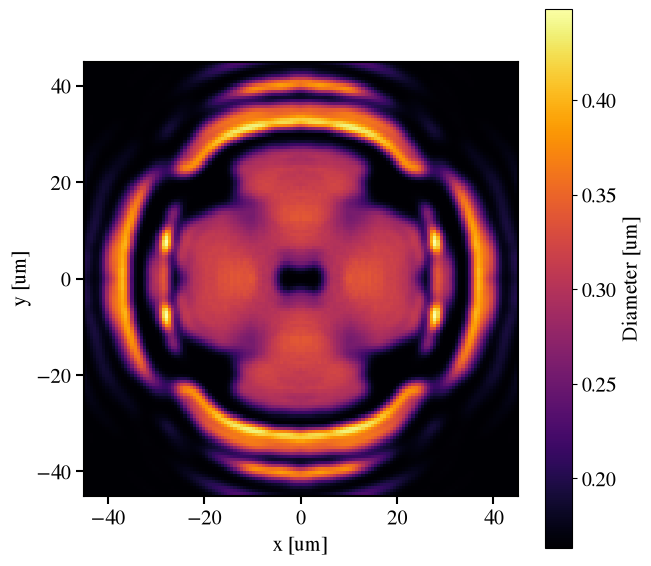

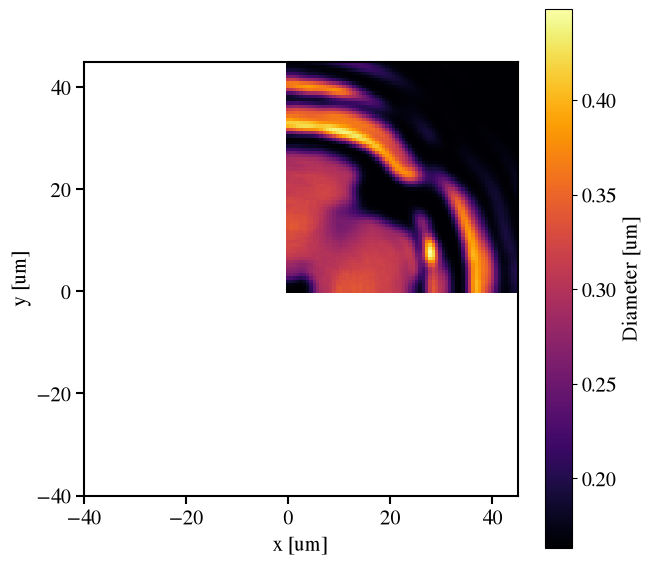

In [43]:
####################################################
#LOAD MASK 1
#___________________________________________________
#load the mask data
mask_1_filename = f"full_meta_data/diam_masks_filtered/mask_1_R_{using_radius_value}_{strategy}.npy"
mask_1 = (np.load(mask_1_filename)).reshape((Nx, Ny))

mask_1_sim = mask_1[sim_mask==1].reshape(Nx_sim, Ny_sim)
fig, ax = plt.subplots()
im = ax.pcolormesh(X_sim, Y_sim, mask_1_sim, cmap='inferno', shading='auto')
ax.set_xlabel('x [um]', fontsize=15)
ax.set_ylabel('y [um]', fontsize=15)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Diameter [um]', fontsize=15)
cbar.ax.tick_params(labelsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
#set the same ticks on both axes
ax.set_xticks((-40,-20,0,20,40))
ax.set_yticks((-40,-20,0,20,40))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
ax.set_aspect('equal')
fig.show()
mask_1_quadrant = mask_1_sim[nx_sim:, ny_sim:]

fig, ax = plt.subplots()
im = ax.pcolormesh(X_sim[nx_sim:, ny_sim:], Y_sim[nx_sim:, ny_sim:], mask_1_quadrant, cmap='inferno', shading='auto')
ax.set_xlabel('x [um]', fontsize=15)
ax.set_ylabel('y [um]', fontsize=15)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Diameter [um]', fontsize=15)
cbar.ax.tick_params(labelsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
ax.set_xticks((-40,-20,0,20,40))
ax.set_yticks((-40,-20,0,20,40))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
ax.set_aspect('equal')
fig.show()


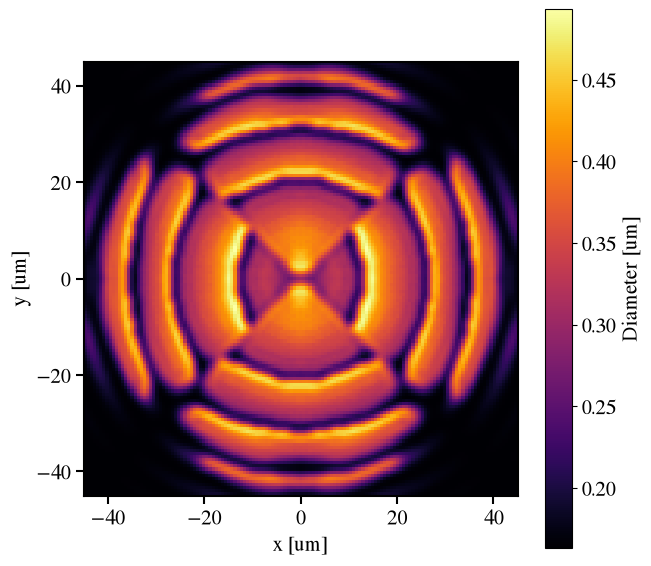

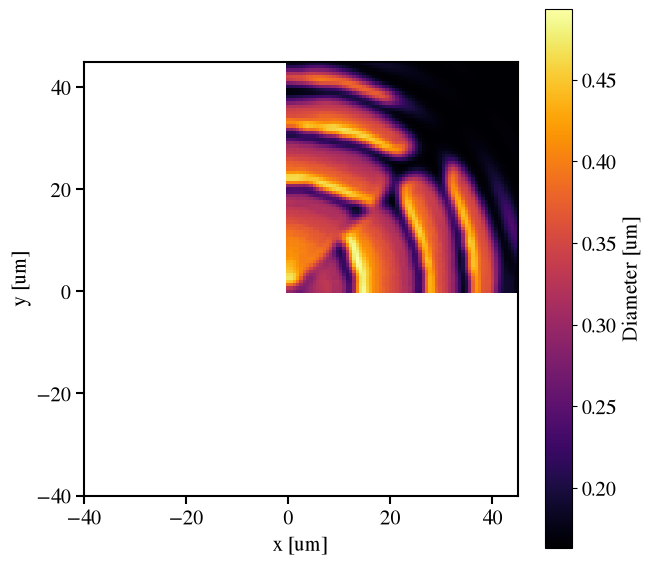

In [44]:
####################################################
#LOAD MASK 2
#___________________________________________________
#load the mask data
mask_2_filename = f"full_meta_data/diam_masks_filtered/mask_2_R_{using_radius_value}_{strategy}.npy"
mask_2 = (np.load(mask_2_filename)).reshape((Nx, Ny))

mask_2_sim = mask_2[sim_mask==1].reshape(Nx_sim, Ny_sim)
fig, ax = plt.subplots()
im = ax.pcolormesh(X_sim, Y_sim, mask_2_sim, cmap='inferno', shading='auto')
ax.set_xlabel('x [um]', fontsize=15)
ax.set_ylabel('y [um]', fontsize=15)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Diameter [um]', fontsize=15)
cbar.ax.tick_params(labelsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
ax.set_xticks((-40,-20,0,20,40))
ax.set_yticks((-40,-20,0,20,40))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
ax.set_aspect('equal')
fig.show()

mask_2_quadrant = mask_2_sim[nx_sim:, ny_sim:]

fig, ax = plt.subplots()
im = ax.pcolormesh(X_sim[nx_sim:, ny_sim:], Y_sim[nx_sim:, ny_sim:], mask_2_quadrant, cmap='inferno', shading='auto')
ax.set_xlabel('x [um]', fontsize=15)
ax.set_ylabel('y [um]', fontsize=15)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Diameter [um]', fontsize=15)
cbar.ax.tick_params(labelsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
ax.set_xticks((-40,-20,0,20,40))
ax.set_yticks((-40,-20,0,20,40))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
ax.set_aspect('equal')
fig.show()


In [7]:
pillars_geo_mask_1 = []
D_vals_mask_1 = []
#theta = unit_cell_mode_phase

for i, x in enumerate(xs_sim_quadrant):
    for j, y in enumerate(ys_sim_quadrant):
        if np.sqrt(x**2 + y**2) > max_available_diameter/2:
            continue
        else:
            #required_diameter = np.interp(mask_1_quadrant[i,j], theta, unit_cell_diameters)
            #retrieve the diameter from the mask1 
            required_diameter = mask_1_quadrant[i,j]
            #round the required diameter up to three decimal places (nm)
            required_diameter = np.round(required_diameter, 3)
            D_vals_mask_1.append(required_diameter)
            pillar_geo = td.Cylinder(center=(x, y, center_sim_1 + h/2), radius=required_diameter/2, length=h)
            pillars_geo_mask_1.append(pillar_geo)
print("Number of pillars in simulation domain: ", len(pillars_geo_mask_1))
pillars_mask_1 = td.Structure(geometry=td.GeometryGroup(geometries=pillars_geo_mask_1), medium=medium_si_pierce)
print("Max pillar diameter:", np.max(D_vals_mask_1))
print("Min pillar diameter:", np.min(D_vals_mask_1))

Number of pillars in simulation domain:  3779
Max pillar diameter: 0.432
Min pillar diameter: 0.163


In [8]:
pillars_geo_mask_2 = []
D_vals_mask_2 = []
#theta = unit_cell_mode_phase

for i, x in enumerate(xs_sim_quadrant):
    for j, y in enumerate(ys_sim_quadrant):
        if np.sqrt(x**2 + y**2) > max_available_diameter/2:
            continue
        else:
            #required_diameter = np.interp(phase_mask_2_quadrant[i,j], theta, unit_cell_diameters)
            #retrieve the diameter from the mask2 
            required_diameter = mask_2_quadrant[i,j]
            #round the required diameter up to three decimal places (nm)
            required_diameter = np.round(required_diameter, 3)
            D_vals_mask_2.append(required_diameter)
            pillar_geo = td.Cylinder(center=(x, y, center_sim_2 -h/2), radius=required_diameter/2, length=h)
            pillars_geo_mask_2.append(pillar_geo)
print("Number of pillars_mask_2 in simulation domain: ", len(pillars_geo_mask_2))
pillars_mask_2 = td.Structure(geometry=td.GeometryGroup(geometries=pillars_geo_mask_2), medium=medium_si_pierce)
print("Max pillar diameter:", np.max(D_vals_mask_2))
print("Min pillar diameter:", np.min(D_vals_mask_2))

Number of pillars_mask_2 in simulation domain:  3779
Max pillar diameter: 0.486
Min pillar diameter: 0.163


In [9]:
#substrate td.Structure definitions
inf_eff = 1e5
substrate_geo_below = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, -inf_eff), rmax=(inf_eff, inf_eff, center_sim_1))
substrate_below = td.Structure(geometry=substrate_geo_below, medium=medium_siO2_malitson)

substrate_geo_above = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, center_sim_2), rmax=(inf_eff, inf_eff, inf_eff))
substrate_above = td.Structure(geometry=substrate_geo_above, medium=medium_siO2_malitson)

all_substrate_geo = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, -inf_eff), rmax=(inf_eff, inf_eff, inf_eff))
all_substrate = td.Structure(geometry=all_substrate_geo, medium=medium_siO2_malitson) 

all_air_geo = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, -inf_eff), rmax=(inf_eff, inf_eff, inf_eff))
all_air = td.Structure(geometry=all_air_geo, medium=air)

In [10]:
#simulation domain size
Lx = max_sim_size
Ly = max_sim_size
Lz = sim_z_size

source_x_size = max_sim_size
source_y_size = max_sim_size

#far field points the projection monitor will compute the field at
Nx_far = 401
Ny_far = 401
xs_far = np.linspace(-Lx/2, Lx/2, Nx_far)
ys_far = np.linspace(-Ly/2, Ly/2, Ny_far)
X_far, Y_far = np.meshgrid(xs_far, ys_far)

In [11]:
#simulation

grid_per_unit_length = 20
grid_x = td.UniformGrid(dl = unit_cell_pitch / grid_per_unit_length)
#grid_x = td.AutoGrid(min_steps_per_wvl=grid_per_unit_length)
grid_y = td.UniformGrid(dl = unit_cell_pitch / grid_per_unit_length)
#grid_y = td.AutoGrid(min_steps_per_wvl=grid_per_unit_length)
grid_z = td.AutoGrid(min_steps_per_wvl=grid_per_unit_length)
grid_spec = td.GridSpec(wavelength=lda0, grid_x = grid_x, grid_y = grid_y, grid_z = grid_z)

#we overlay a box structure over the position of the pillars. This is done for the following reason.
#The meshing over the pillars requires many steps, since the refractive index changes
#from pillar to air. Instead of having to parse all these transitions, especially since we
#have a large number of pillars, we can simply overlay a box of the same material as the pillars.
#In this way, preprocessing becomes faster because all the region is treated uniformly. 
# The material is the same as the pillars, i.e., silicon
#to ensure the mesh is finer, compared to the surrounding air.

grid_spec_0 = grid_spec.copy()

grid_spec_1 = grid_spec.copy(
    update = dict(
        override_structures=[
            td.Structure(
                geometry=td.Box.from_bounds(
                    rmin = (-td.inf, -td.inf, center_sim_1),
                    rmax = (td.inf, td.inf, center_sim_1 + h)
                ),
                medium = medium_si_pierce,
            )
        ]
    )
)

grid_spec_2 = grid_spec.copy(
    update = dict(
        override_structures=[
            td.Structure(
                geometry=td.Box.from_bounds(
                    rmin = (-td.inf, -td.inf, center_sim_2-h),
                    rmax = (td.inf, td.inf, center_sim_2)
                ),
                medium = medium_si_pierce,
            )
        ]
    )
)

In [12]:
source_position_0 = 0
source_position_1 = center_sim_1 - (lda0 / 2)
source_position_2 = center_sim_2 - h - (lda0 / 2)

proj_monitor_position_0 = lda0 / 2
proj_monitor_position_1 = center_sim_1 + h + lda0 / 2
proj_monitor_position_2 = center_sim_2 + lda0 / 2

projection_start_position_0 = 0
projection_start_position_1 = center_sim_1 + h
projection_start_position_2 = center_sim_2 + h

projection_distance_0 = source_position_1 - projection_start_position_0
projection_distance_1 = source_position_2 - projection_start_position_1
projection_distance_2 = output_plane_position - projection_start_position_2

monitor_proj_0 = td.FieldProjectionCartesianMonitor(
    center=[0, 0, proj_monitor_position_0],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="ff_proj_monitor_0",
    proj_axis=2,
    proj_distance=projection_distance_0,
    x=xs_far,
    y=ys_far,
    custom_origin=(0, 0, projection_start_position_0),
    far_field_approx=False,
)

monitor_proj_1 = td.FieldProjectionCartesianMonitor(
    center=[0, 0,  proj_monitor_position_1],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="ff_proj_monitor_1",
    proj_axis=2,
    proj_distance=projection_distance_1,
    x=xs_far,
    y=ys_far,
    custom_origin=(0, 0, projection_start_position_1),
    far_field_approx=False,
)

monitor_proj_2 = td.FieldProjectionCartesianMonitor(
    center=[0, 0,  proj_monitor_position_2],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="ff_proj_monitor_2",
    proj_axis=2,
    proj_distance=projection_distance_2,
    x=xs_far,
    y=ys_far,
    custom_origin=(0, 0, projection_start_position_2),
    far_field_approx=False,
)

In [13]:
####################################################
####################################################
mnt_yz_0 = td.FieldMonitor(
    center=(0, 0, center_sim_0), 
    size=(0, td.inf, td.inf), 
    freqs=freq_list,
    name="field_yz_0",
)

transmittance_flux_monitor_0 = td.FluxMonitor(
    center=[0, 0, center_sim_0 + lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="transmittance_flux_monitor_0",
)

reflectance_flux_monitor_0 = td.FluxMonitor(
    center=[0, 0, center_sim_0 - (lda0/2)],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="reflectance_flux_monitor_0",
)
####################################################
####################################################
mnt_yz_1 = td.FieldMonitor(
    center=(0, 0, center_sim_1), 
    size=(0, td.inf, td.inf), 
    freqs=freq_list,
    name="field_yz_1",
)

transmittance_flux_monitor_1 = td.FluxMonitor(
    center=[0, 0, center_sim_1 + h + lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="transmittance_flux_monitor_1",
)

reflectance_flux_monitor_1 = td.FluxMonitor(
    center=[0, 0, center_sim_1 - (lda0/2 + 0.1)],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="reflectance_flux_monitor_1",
)
####################################################
####################################################
mnt_yz_2 = td.FieldMonitor(
    center=(0, 0, center_sim_2), 
    size=(0, td.inf, td.inf), 
    freqs=freq_list,
    name="field_yz_2",
)

transmittance_flux_monitor_2 = td.FluxMonitor(
    center=[0, 0, center_sim_2 + lda0 / 2],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="transmittance_flux_monitor_2",
)

reflectance_flux_monitor_2 = td.FluxMonitor(
    center=[0, 0, center_sim_2 - h - 1.1*lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=freq_list,
    name="reflectance_flux_monitor_2",
)
####################################################
####################################################

Fitted beam waist: 7.069358088547971


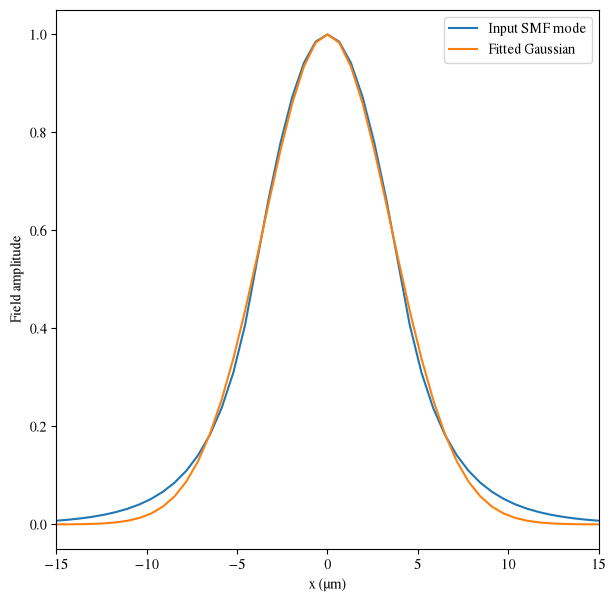

In [14]:
# Gaussian source fitted to the analytical SMF mode
# to extract the beam waist
input_SMF_mode_filename = 'full_meta_data/input_field/SMF_LP01_field_distribution_lda_1550_N_1025.npy'

input_SMF_mode = np.real(np.load(input_SMF_mode_filename))

from scipy.optimize import curve_fit

def gaussian_2d(x, w0):
    return np.exp(-2 * (x**2 + 0**2) / w0**2).ravel()
input_SMF_mode = input_SMF_mode / np.max(np.abs(input_SMF_mode))

input_SMF_mode_slice = input_SMF_mode[:, input_SMF_mode.shape[1] // 2]

popt, _ = curve_fit(f=gaussian_2d, xdata=xs, ydata=input_SMF_mode_slice, p0=[1])
beam_waist = popt[0]

print("Fitted beam waist:", beam_waist)
y0_index = input_SMF_mode.shape[1] // 2
plt.plot(xs, input_SMF_mode[:, y0_index], label='Input SMF mode')
plt.plot(xs, np.exp(-2 * xs**2 / beam_waist**2), label='Fitted Gaussian')
plt.xlabel('x (µm)')
plt.xlim(-15, 15)
plt.ylabel('Field amplitude')
plt.legend()
plt.show()
plt.close()


In [15]:
run_time = 5e-12
source_bandwidth = 0.45
source_time = td.GaussianPulse(freq0=freq0, fwidth=fwidth * source_bandwidth, phase=0)

In [16]:
# custom source defined using a field dataset constructed
# on the analytical fiber mode
# custom_src_0 = td.CustomFieldSource(
#     source_time = source_time,
#     center = (0, 0, source_position_0),
#     size = (source_x_size, source_y_size, 0),
#     field_dataset = dataset_input_EH_0
# )


# This is a Tidy3D Gaussian beam source fitted to the SMF mode.
# This source is used to exclude any possible contamination from
# the ASM method. Basically, the only imported quantities are
# the unit cell diameters. Everything else is pure stock Tidy3D.
# The fitted mode is basically identical to the original SMF mode,
# so I expect some variations, but hopefully they are not disruptive.

fitted_smf_source = td.GaussianBeam(
    name='fitted_smf_source',
    source_time = source_time,
    num_freqs = 1,
    center = (0, 0, source_position_0),
    size = (source_x_size, source_y_size, 0), 
    waist_radius = beam_waist,
    direction='+',
)

In [17]:
Lx_temp = 60
Ly_temp = 60
sim0 = td.Simulation(
    center=[0, 0, center_sim_0],
    size=[Lx_temp, Ly_temp, Lz],
    grid_spec=grid_spec_0,
    structures=[all_substrate],
    sources=[fitted_smf_source],
    monitors=[transmittance_flux_monitor_0, reflectance_flux_monitor_0, monitor_proj_0, mnt_yz_0],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

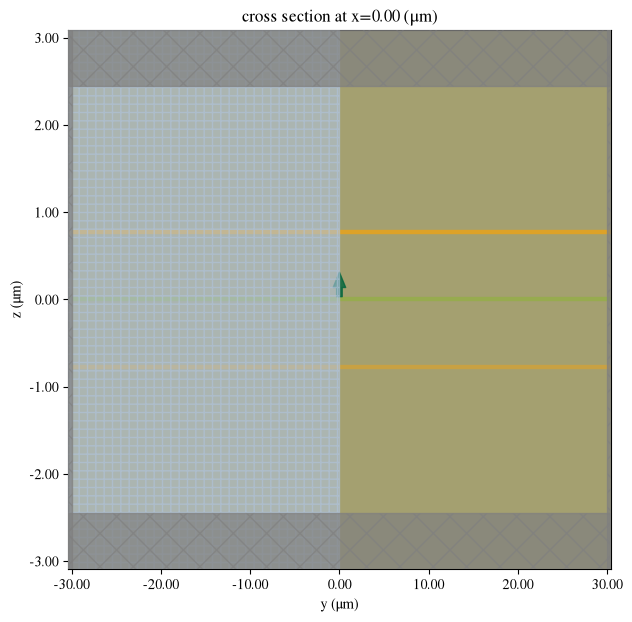

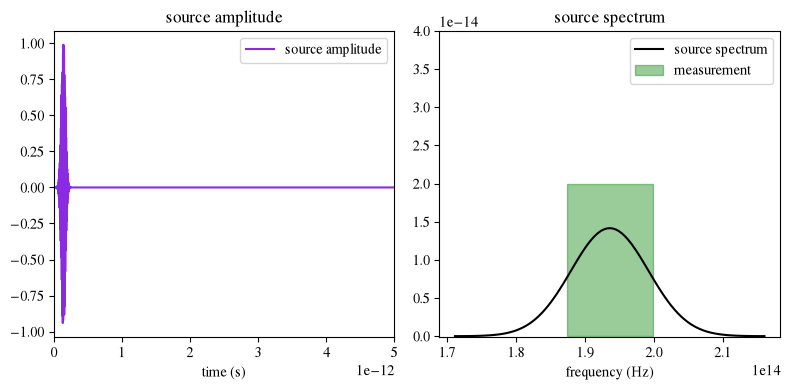

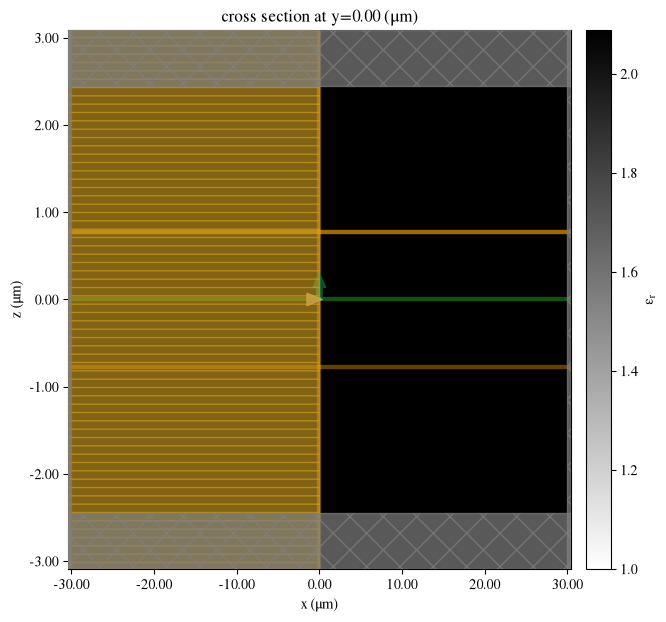

09:38:52 CET Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=12617221;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ae880944-89ab-479d-bef2-37195ee6d6d2\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=12617222;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ae880944-89ab-479d-bef2-37195ee6d6d2\taskId]8;;\]8;id=12617221;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ae880944-89ab-479d-bef2-37195ee6d6d2\=]8;;\]8;id=12617223;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ae880944-89ab-479d-bef2-37195ee6d6d2\fdve]8;;\]8;id=12617221;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ae880944-89ab-479d-bef2-37195ee6d6d2\-ae880944-89a]8;;\
             ]8;id=12617221;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ae880944-89ab-479d-bef2-37195ee6d6d2\b-479d-bef2-37195ee6d6d2']8;;\.

09:38:54 CET Estimated FlexCredit cost: 4.967. Minimum cost depends on task     
             execution details. Use 'web.real_cost(task_id)' to get the billed  
             FlexCredit cost after a simulation run.

In [ ]:
# Check simulation domain
fig, ax = plt.subplots()
sim0.plot(x=0, ax=ax,)
sim0.plot_grid(x=0, ax=ax, finest_grid_region_alpha=0)
ax.set_aspect('auto')
plt.show()
plt.close()

# fig, ax = plt.subplots()
# sim0.plot(z=h/2, ax=ax, rasterized=True)
# plt.xlim(0,Lx/2)
# plt.ylim(0,Ly/2)
# plt.show()

# Check probe and source
f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(8, 4))
ax1 = sim0.sources[0].source_time.plot(times=np.linspace(0, sim0.run_time, 5001), ax=ax1)
ax1.set_xlim(0, sim0.run_time)
ax1.legend(("source amplitude",))
ax2 = sim0.sources[0].source_time.plot_spectrum(
    times=np.linspace(0, sim0.run_time, 5001), val="abs", ax=ax2
)
fill_max = 2e-14  # 10e-16
ymax = 4e-14  # 20e-16
ax2.fill_between(
    (f_min, f_max), [-0e-16, -0e-16], [fill_max, fill_max], alpha=0.4, color="g"
)
ax2.legend(("source spectrum", "measurement"))
ax2.set_ylim(-1e-16, ymax)
plt.show()
plt.close()

#check materials
fig, ax = plt.subplots()
sim0.plot_eps(y=0, freq=freq_0, ax=ax)
ax.set_aspect('auto')
plt.show()
plt.close()

job = web.Job(simulation=sim0, task_name="estimate_source_to_MS1")
estimated_cost = web.estimate_cost(job.task_id)

In [19]:
sim_data_0 = job.run(path=f"full_meta_results/full_meta0_R_{using_radius_value}_{strategy}.hdf5")

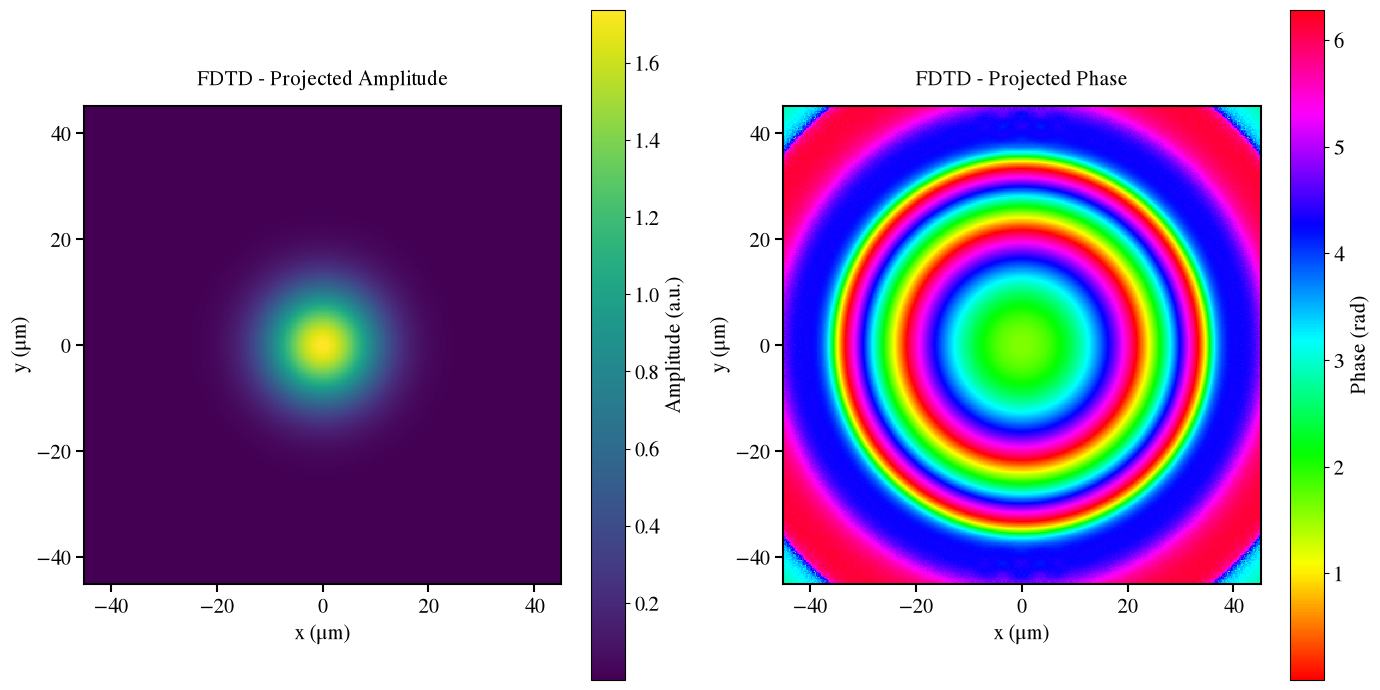

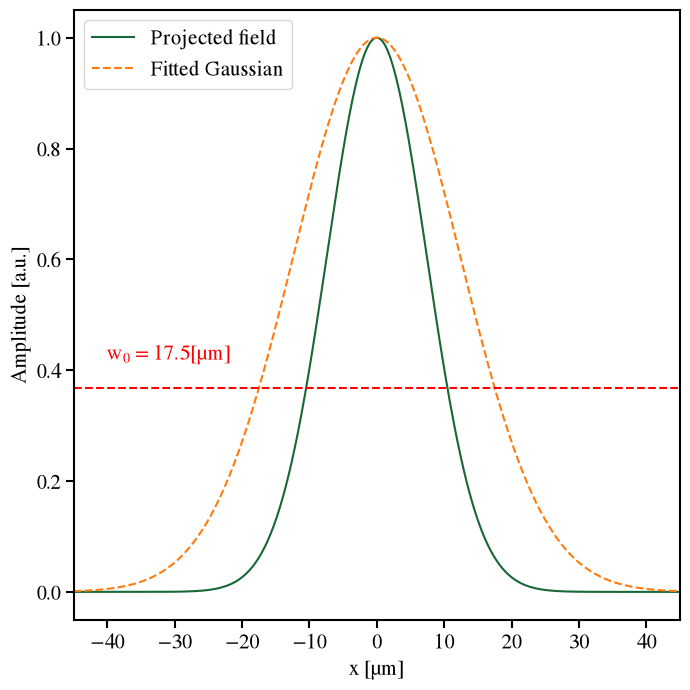

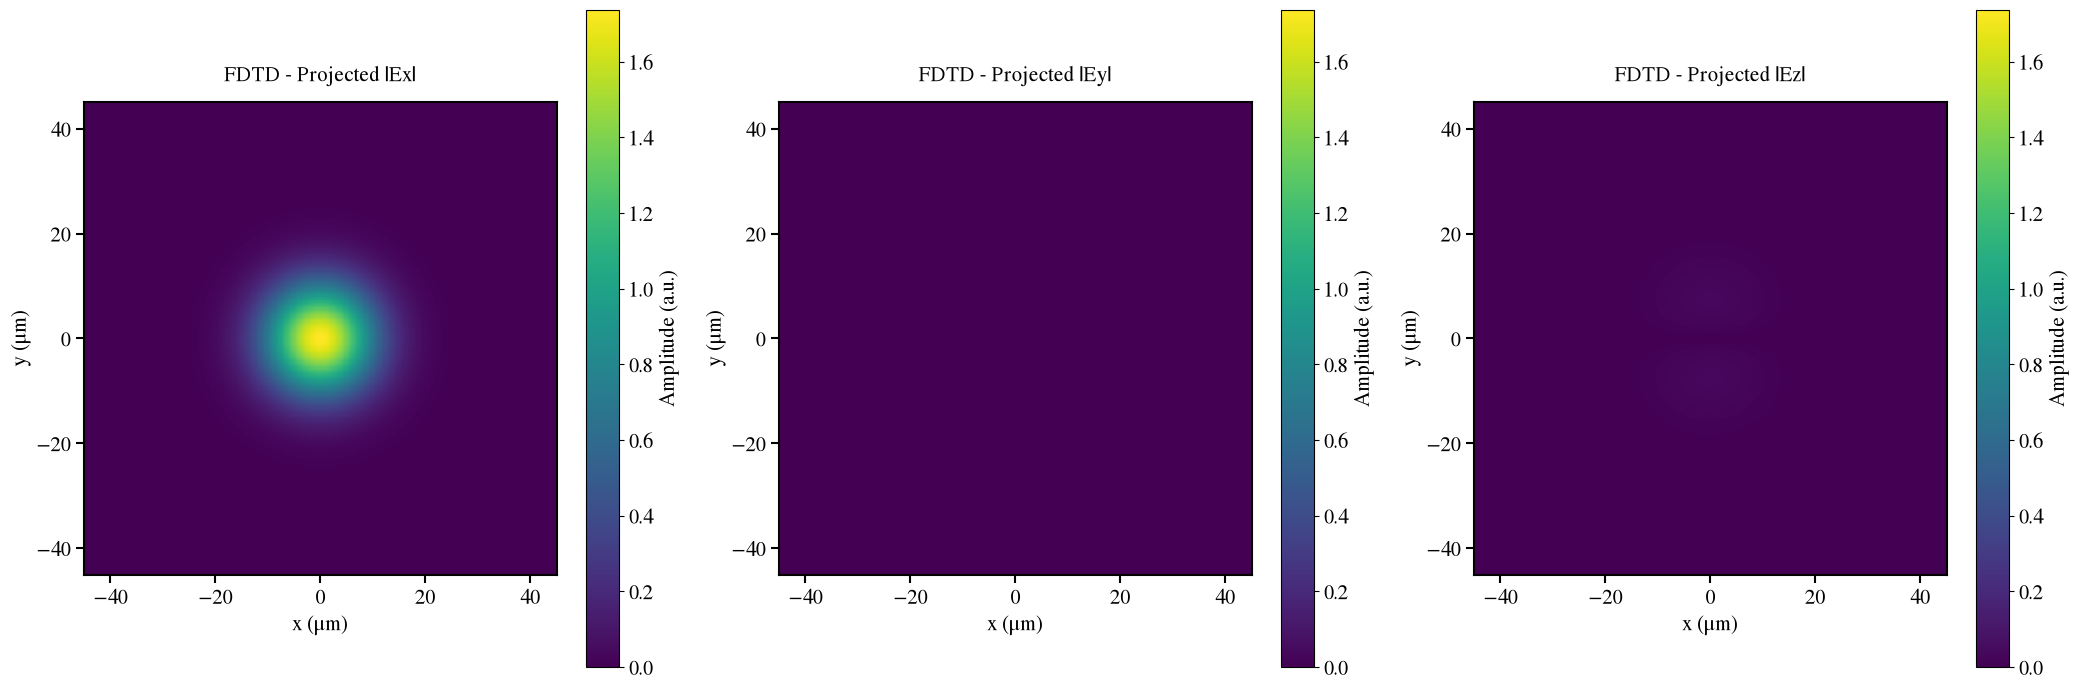

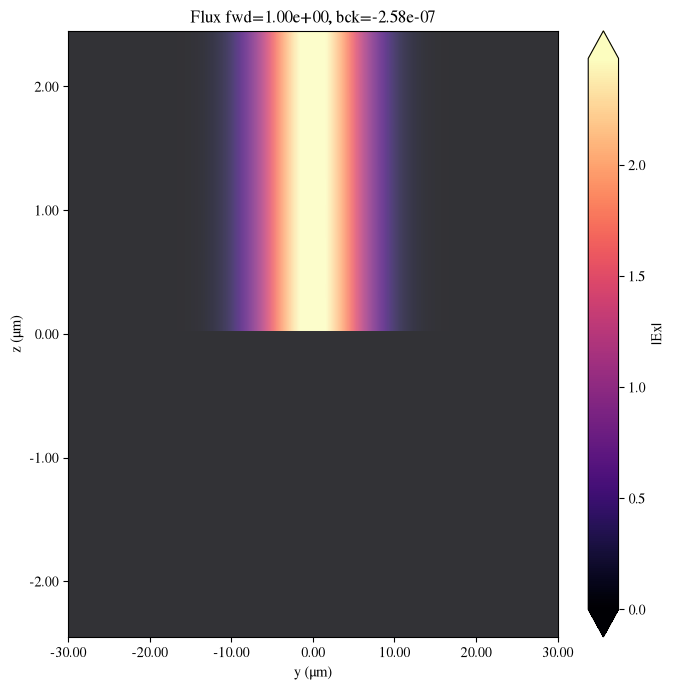

FDTD forward flux: 0.99985271692276


In [20]:
sim_data_0 = SimulationData.from_file(fname=f"full_meta_results/full_meta0_R_{using_radius_value}_{strategy}.hdf5")

#observe fields at the central frequency (freq0), at the position source_position_1
#save the full field data
proj_fields_sim0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian

proj_Ex_field_0 = proj_fields_sim0.Ex.sel(f=freq0, z=source_position_1)
proj_Ey_field_0 = proj_fields_sim0.Ey.sel(f=freq0, z=source_position_1)
proj_Ez_field_0 = proj_fields_sim0.Ez.sel(f=freq0, z=source_position_1)
proj_Hx_field_0 = proj_fields_sim0.Hx.sel(f=freq0, z=source_position_1)
proj_Hy_field_0 = proj_fields_sim0.Hy.sel(f=freq0, z=source_position_1)
proj_Hz_field_0 = proj_fields_sim0.Hz.sel(f=freq0, z=source_position_1)

import pickle
#pickle save the complete fields (all components, all frequencies)
with open(f"full_meta_results/proj_field_sim0_R_{using_radius_value}_{strategy}.pkl", "wb") as f:
    pickle.dump(proj_fields_sim0, f)

fig, ax = plt.subplots(1,2,figsize=(14, 7))

im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_0), shading='auto', cmap='viridis',rasterized=True)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_title("FDTD - Projected Amplitude", fontsize=15, pad=15)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="Amplitude (a.u.)")
cbar0.set_label("Amplitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, (np.angle(proj_Ex_field_0)+2*np.pi)%(2*np.pi), shading='auto', cmap='hsv',rasterized=True)
ax[1].set_title("FDTD - Projected Phase", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="Phase (rad)")
cbar1.set_label("Phase (rad)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(f"full_meta_results/plots/full_meta0_proj_Ex_field_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)

#slice of the projected Ex component
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(X_far[X_far.shape[0]//2,:], np.abs(proj_Ex_field_0[X_far.shape[0]//2,:]) / np.max(np.abs(proj_Ex_field_0[X_far.shape[0]//2,:])), label='Projected field')
fitted_mode_diameter = 35
fitted_beam_waist = fitted_mode_diameter / 2
rho_squared_proj = X_far ** 2 + Y_far ** 2
fitted_gaussian = np.exp(- rho_squared_proj / fitted_beam_waist**2)
ax.plot(X_far[X_far.shape[0]//2,:], fitted_gaussian[X_far.shape[0]//2,:] / np.max(fitted_gaussian[X_far.shape[0]//2,:]), linestyle='--', label='Fitted Gaussian')
ax.axhline(np.exp(-1), color='r', linestyle='--')
ax.text(-40, np.exp(-1) + 0.05, f'$w_0 = {fitted_beam_waist} [µm]$', color='r', fontsize=15)
ax.set_xlabel('x [µm]',fontsize=15)
ax.set_ylabel('Amplitude [a.u.]',fontsize=15)
ax.set_xlim(X_far[X_far.shape[0]//2,0], X_far[X_far.shape[0]//2,-1])
ax.legend(fontsize=15, loc='upper left')
ax.tick_params(labelsize=15, width=1.5, length=6)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(f"full_meta_results/plots/full_meta0_proj_Ex_field_cross_section_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)

fig, ax = plt.subplots(1,3,figsize=(21, 7))
im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_0), shading='auto', cmap='viridis',rasterized=True, vmin = 0, vmax = np.max(np.abs(proj_Ex_field_0)))
ax[0].set_title("FDTD - Projected |Ex|", fontsize=15, pad=15)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="Amplitude (a.u.)")
cbar0.set_label("Amplitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, np.abs(proj_Ey_field_0), shading='auto', cmap='viridis',rasterized=True, vmin = 0, vmax = np.max(np.abs(proj_Ex_field_0)))
ax[1].set_title("FDTD - Projected |Ey|", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="Amplitude (a.u.)")
cbar1.set_label("Amplitude (a.u.)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

im2 = ax[2].pcolormesh(X_far, Y_far, np.abs(proj_Ez_field_0), shading='auto', cmap='viridis',rasterized=True, vmin = 0, vmax = np.max(np.abs(proj_Ex_field_0)))
ax[2].set_title("FDTD - Projected |Ez|", fontsize=15, pad=15)
ax[2].set_xlabel("x (μm)", fontsize=15,)
ax[2].set_ylabel("y (μm)", fontsize=15,)
ax[2].set_aspect('equal')
cbar2 = plt.colorbar(im2, ax=ax[2], label="Amplitude (a.u.)")
cbar2.set_label("Amplitude (a.u.)", fontsize=15)
cbar2.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(f"full_meta_results/plots/full_meta0_proj_E_field_intensity_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)

#plot the flux to observe source directionality
fig, ax = plt.subplots(1)
f_sel_to_plot = f_cen
#get flux data at selected frequency
trans_flux = sim_data_0['transmittance_flux_monitor_0'].flux.sel(f=f_sel_to_plot).item()
refl_flux = sim_data_0['reflectance_flux_monitor_0'].flux.sel(f=f_sel_to_plot).item()
sim_data_0.plot_field("field_yz_0", f=f_sel_to_plot, field_name="Ex", val="abs", ax=ax)

ax.set_xlim([-sim0.size[0] / 2, sim0.size[0] / 2])
ax.set_ylim([-sim0.size[2] / 2, sim0.size[2] / 2])
ax.set_title(
    f"Flux fwd={float(trans_flux):1.2e}, bck={float(refl_flux):1.2e}"
)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()
plt.close()
forward_flux_0 = float(trans_flux)
print("FDTD forward flux:", forward_flux_0)

In [21]:
#pickle import the input field (just before MS1)
import pickle
with open(f"full_meta_results/proj_field_sim0_R_{using_radius_value}_{strategy}.pkl", "rb") as f:
    input_fields_before_MS1 = pickle.load(f)

In [22]:
dataset_input_EH_1 = td.FieldDataset(
    Ex = td.ScalarFieldDataArray(
         input_fields_before_MS1.Ex.sel(f=[freq0]),
    ),
    Ey = td.ScalarFieldDataArray(
        input_fields_before_MS1.Ey.sel(f=[freq0]),
    ),
    Ez = td.ScalarFieldDataArray(
        input_fields_before_MS1.Ez.sel(f=[freq0]),
    ),
    Hx = td.ScalarFieldDataArray(
        input_fields_before_MS1.Hx.sel(f=[freq0]),
    ),
    Hy = td.ScalarFieldDataArray(
        input_fields_before_MS1.Hy.sel(f=[freq0]),
    ),
    Hz = td.ScalarFieldDataArray(
        input_fields_before_MS1.Hz.sel(f=[freq0]),
    ),
)

#sources must be defined at one frequency (as per Tidy3d docs)
#we therefore select the central frequency (freq0)
custom_src_1 = td.CustomFieldSource(
    source_time = source_time,
    center = (0, 0, source_position_1),
    size = (source_x_size, source_y_size, 0),
    field_dataset = dataset_input_EH_1
)

09:39:03 CET WARNING: Override structures take no effect along x-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Override structures take no effect along y-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

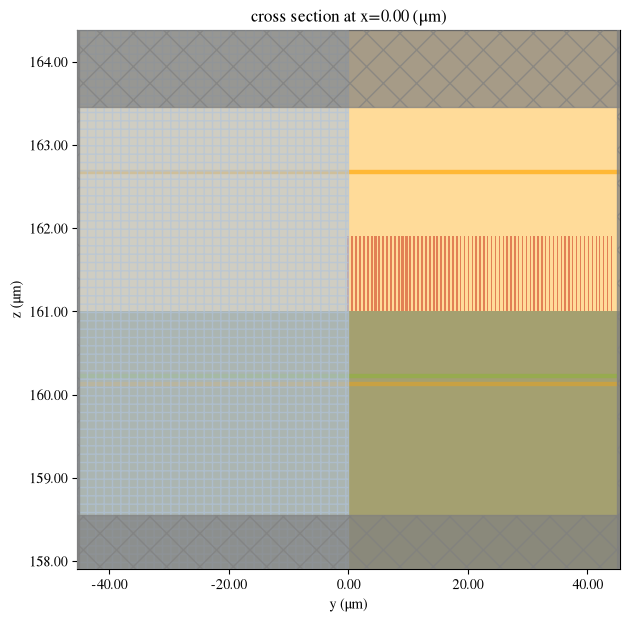

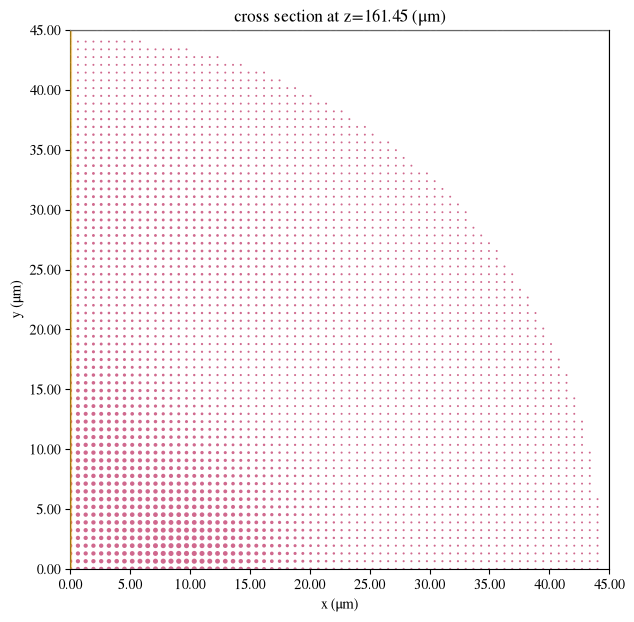

In [ ]:
sim1 = td.Simulation(
    center=[0, 0, center_sim_1],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_1,
    structures=[substrate_below, pillars_mask_1],
    sources=[custom_src_1],
    monitors=[reflectance_flux_monitor_1, transmittance_flux_monitor_1, monitor_proj_1, mnt_yz_1],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim1.plot(x=0, ax=ax,)
sim1.plot_grid(x=0, ax=ax, finest_grid_region_alpha=0)
ax.set_aspect('auto')
plt.show()
plt.close()

fig, ax = plt.subplots()
sim1.plot(z=center_sim_1 + h/2, ax=ax, rasterized=True)
plt.xlim(0,Lx/2)
plt.ylim(0,Ly/2)
plt.show()
plt.close()

In [24]:
job = web.Job(simulation=sim1, task_name="full_meta1")
estimated_cost = web.estimate_cost(job.task_id)

09:39:10 CET Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=12617227;https://tidy3d.simulation.cloud/workbench?taskId=fdve-49903fd8-99e2-4a0b-ab66-12254d6b9959\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=12617228;https://tidy3d.simulation.cloud/workbench?taskId=fdve-49903fd8-99e2-4a0b-ab66-12254d6b9959\taskId]8;;\]8;id=12617227;https://tidy3d.simulation.cloud/workbench?taskId=fdve-49903fd8-99e2-4a0b-ab66-12254d6b9959\=]8;;\]8;id=12617229;https://tidy3d.simulation.cloud/workbench?taskId=fdve-49903fd8-99e2-4a0b-ab66-12254d6b9959\fdve]8;;\]8;id=12617227;https://tidy3d.simulation.cloud/workbench?taskId=fdve-49903fd8-99e2-4a0b-ab66-12254d6b9959\-49903fd8-99e]8;;\
             ]8;id=12617227;https://tidy3d.simulation.cloud/workbench?taskId=fdve-49903fd8-99e2-4a0b-ab66-12254d6b9959\2-4a0b-ab66-12254d6b9959']8;;\.

09:39:14 CET Estimated FlexCredit cost: 13.349. Minimum cost depends on task    
             execution details. Use 'web.real_cost(task_id)' to get the billed  
             FlexCredit cost after a simulation run.

In [25]:
sim_data_1 = job.run(path=f"full_meta_results/full_meta1_R_{using_radius_value}_{strategy}.hdf5")

09:39:16 CET WARNING: Override structures take no effect along x-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Override structures take no effect along y-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

09:39:17 CET WARNING: Override structures take no effect along x-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Override structures take no effect along y-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

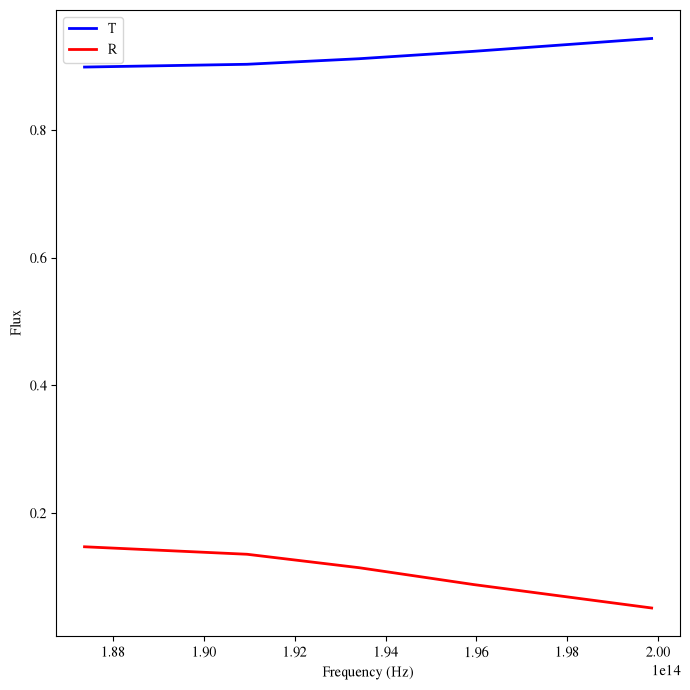

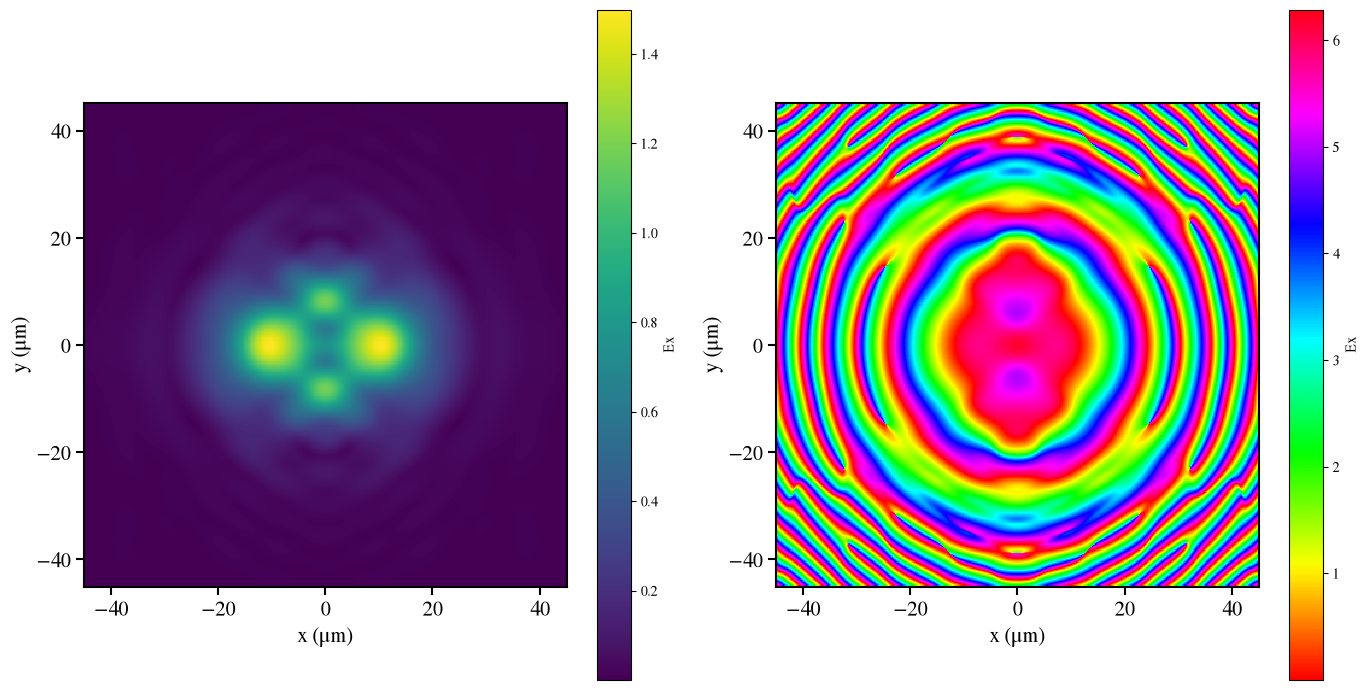

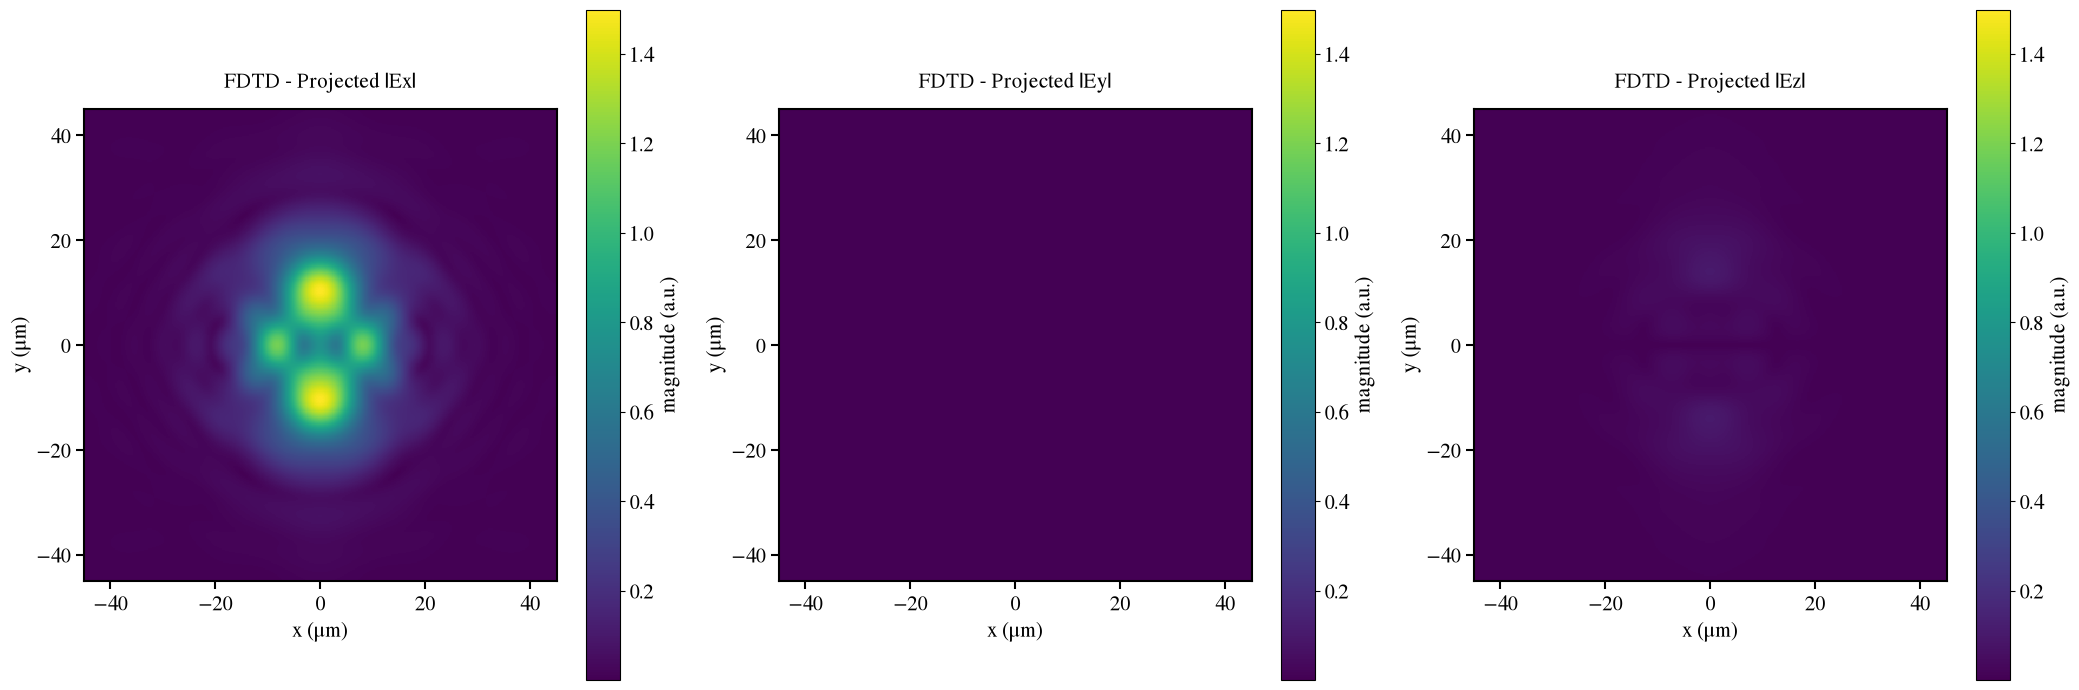

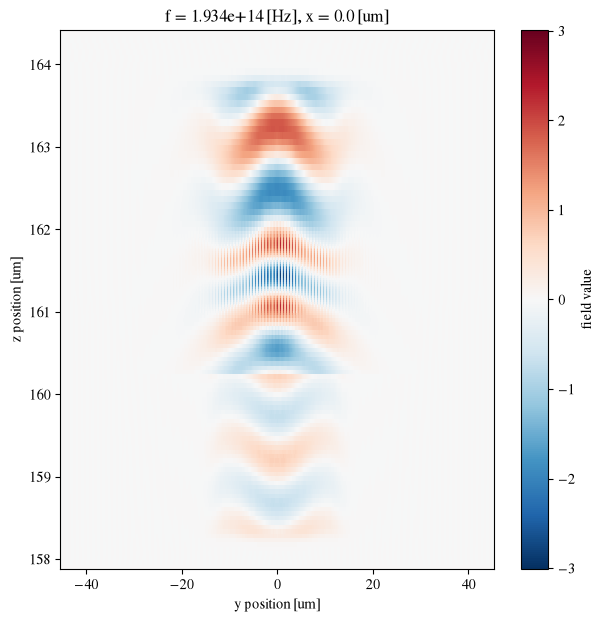

In [26]:
sim_data_1 = SimulationData.from_file(fname=f"full_meta_results/full_meta1_R_{using_radius_value}_{strategy}.hdf5")

#plot reflectance and transmittance fluxes vs. frequency
forward_flux_1 = sim_data_1['transmittance_flux_monitor_1'].flux
backward_flux_1 = sim_data_1['reflectance_flux_monitor_1'].flux * (-1)
fig, ax = plt.subplots()
forward_flux_1.plot(ax=ax, x='f', label='T', color='b', linewidth=2)
backward_flux_1.plot(ax=ax, x='f', label='R', color='r', linewidth=2)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Flux")
ax.legend()
plt.tight_layout()
plt.show()
plt.close()

proj_fields_sim1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian
with open(f"full_meta_results/proj_fields_sim1_R_{using_radius_value}_{strategy}.pkl", "wb") as f:
    pickle.dump(proj_fields_sim1, f)


proj_Ex_field_1 = proj_fields_sim1.Ex.sel(f=freq0, z=source_position_2-projection_start_position_1)
proj_Ey_field_1 = proj_fields_sim1.Ey.sel(f=freq0, z=source_position_2-projection_start_position_1)
proj_Ez_field_1 = proj_fields_sim1.Ez.sel(f=freq0, z=source_position_2-projection_start_position_1)

fig, ax = plt.subplots(1,2,figsize=(14, 7))
np.abs(proj_Ex_field_1).plot(ax=ax[0], x = 'x', y = 'y', rasterized=True)
phase_Ex_field_1 = proj_Ex_field_1.copy(
    data = np.mod(np.angle(proj_Ex_field_1), 2*np.pi)
)
phase_Ex_field_1.plot(ax=ax[1], x = 'x', y = 'y', rasterized=True, cmap='hsv')
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
ax[0].set_title("")
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
ax[1].set_title("")
for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(f"full_meta_results/plots/full_meta1_proj_Ex_field_1_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)

fig, ax = plt.subplots(1,3,figsize=(21, 7))
im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_1), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_1).max(), vmin = np.abs(proj_Ex_field_1).min())
ax[0].set_title("FDTD - Projected |Ex|", fontsize=15, pad=15)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="magnitude (a.u.)")
cbar0.set_label("magnitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, np.abs(proj_Ey_field_1), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_1).max(), vmin = np.abs(proj_Ex_field_1).min())
ax[1].set_title("FDTD - Projected |Ey|", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="magnitude (a.u.)")
cbar1.set_label("magnitude (a.u.)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

im2 = ax[2].pcolormesh(X_far, Y_far, np.abs(proj_Ez_field_1), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_1).max(), vmin = np.abs(proj_Ex_field_1).min())
ax[2].set_title("FDTD - Projected |Ez|", fontsize=15, pad=15)
ax[2].set_xlabel("x (μm)", fontsize=15,)
ax[2].set_ylabel("y (μm)", fontsize=15,)
ax[2].set_aspect('equal')
cbar2 = plt.colorbar(im2, ax=ax[2], label="magnitude (a.u.)")
cbar2.set_label("magnitude (a.u.)", fontsize=15)
cbar2.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(f"full_meta_results/plots/full_meta1_proj_E_field_intensity_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)

#plot: real part of the Ex field on the yz plane
fig, ax = plt.subplots(1)
sim_data_1["field_yz_1"].Ex.sel(f=[freq0], x=0).real.plot(ax=ax, y='z')

In [27]:
#pickle load the projected fields before MS2
with open(f"full_meta_results/proj_fields_sim1_R_{using_radius_value}_{strategy}.pkl", "rb") as f:
    input_fields_before_MS2 = pickle.load(f)


#change the z coordinate to account for the custom origin on projection
#monitors. The actual z coordinate is the projection start position + projection distance = source_position_2.
input_fields_before_MS2 = input_fields_before_MS2.assign_coords(z=input_fields_before_MS2.z + projection_start_position_1)

dataset_input_EH_2 = td.FieldDataset(
    Ex = td.ScalarFieldDataArray(
        input_fields_before_MS2.Ex.sel(f=[freq0]),
    ),
    Ey = td.ScalarFieldDataArray(
        input_fields_before_MS2.Ey.sel(f=[freq0]),
    ),
    Ez = td.ScalarFieldDataArray(
        input_fields_before_MS2.Ez.sel(f=[freq0]),
    ),
    Hx = td.ScalarFieldDataArray(
        input_fields_before_MS2.Hx.sel(f=[freq0]),
    ),
    Hy = td.ScalarFieldDataArray(
        input_fields_before_MS2.Hy.sel(f=[freq0]),
    ),
    Hz = td.ScalarFieldDataArray(
        input_fields_before_MS2.Hz.sel(f=[freq0]),
    ),
)

custom_src_2 = td.CustomFieldSource(
    source_time = source_time,
    center = (0, 0, source_position_2),
    size = (source_x_size, source_y_size, 0),
    field_dataset = dataset_input_EH_2
)

09:39:24 CET WARNING: Override structures take no effect along x-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Override structures take no effect along y-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

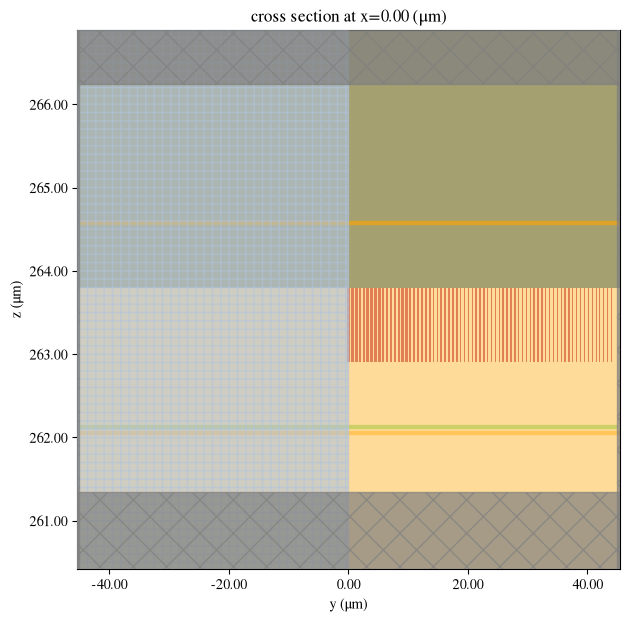

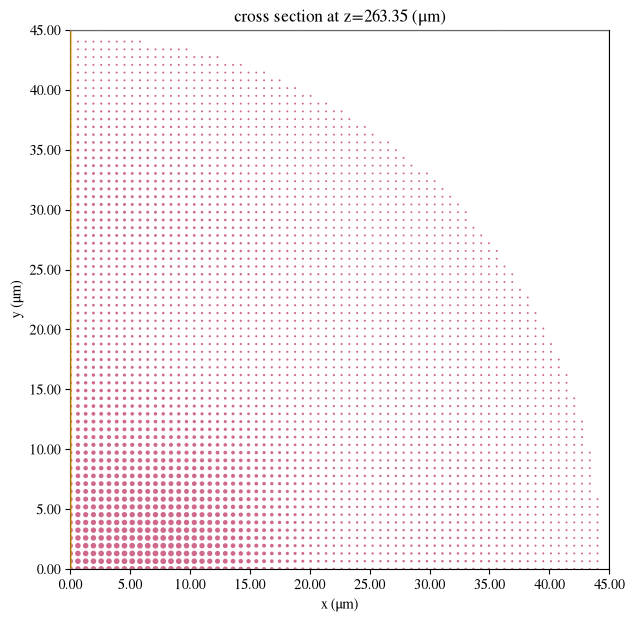

In [ ]:
sim2 = td.Simulation(
    center=[0, 0, center_sim_2],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_2,
    structures=[substrate_above, pillars_mask_2],
    sources=[custom_src_2, ],
    monitors=[reflectance_flux_monitor_2, transmittance_flux_monitor_2, monitor_proj_2, mnt_yz_2],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim2.plot(x=0, ax=ax, rasterized=True)
sim2.plot_grid(x=0, ax=ax, finest_grid_region_alpha=0)
ax.set_aspect('auto')
plt.show()
plt.close()

fig, ax = plt.subplots()
sim2.plot(z=center_sim_2 - h/2, ax=ax, rasterized=True)
plt.xlim(0,Lx/2)
plt.ylim(0,Ly/2)
plt.show()
plt.close()


In [29]:
job_2 = web.Job(simulation=sim2, task_name="full_meta2")
estimated_cost = web.estimate_cost(job_2.task_id)

09:39:31 CET Created task 'full_meta2' with resource_id                         
             'fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=12617233;https://tidy3d.simulation.cloud/workbench?taskId=fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=12617234;https://tidy3d.simulation.cloud/workbench?taskId=fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e\taskId]8;;\]8;id=12617233;https://tidy3d.simulation.cloud/workbench?taskId=fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e\=]8;;\]8;id=12617235;https://tidy3d.simulation.cloud/workbench?taskId=fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e\fdve]8;;\]8;id=12617233;https://tidy3d.simulation.cloud/workbench?taskId=fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e\-079a3b64-8ca]8;;\
             ]8;id=12617233;https://tidy3d.simulation.cloud/workbench?taskId=fdve-079a3b64-8ca7-4842-95c4-e4e0364e876e\7-4842-95c4-e4e0364e876e']8;;\.

             Task folder: ]8;id=12617238;https://tidy3d.simulation.cloud/folders/folder-6fa00d15-cb0e-4116-8177-44b5787077db\'default']8;;\.

Output()

09:39:44 CET Estimated FlexCredit cost: 13.321. Minimum cost depends on task    
             execution details. Use 'web.real_cost(task_id)' to get the billed  
             FlexCredit cost after a simulation run.

In [30]:
sim_data_2 = job_2.run(path=f"full_meta_results/full_meta2_R_{using_radius_value}_{strategy}.hdf5")

09:39:45 CET status = success

Output()

09:39:49 CET Loading results from                                               
             full_meta_results/full_meta2_R_11_0_epigraph.hdf5

09:39:50 CET WARNING: Override structures take no effect along x-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Override structures take no effect along y-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

09:39:52 CET WARNING: Override structures take no effect along x-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

             WARNING: Override structures take no effect along y-axis. If       
             intending to apply override structures to this axis, use 'AutoGrid'
             or 'QuasiUniformGrid'.                                             

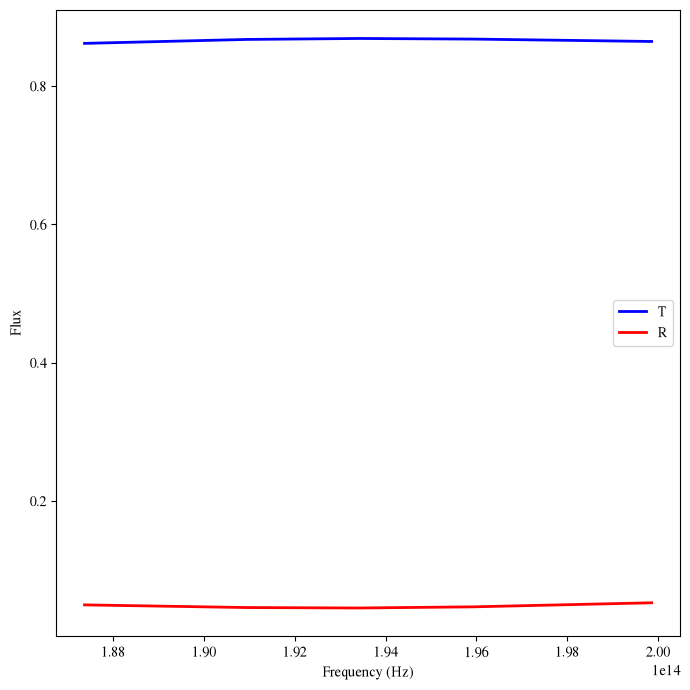

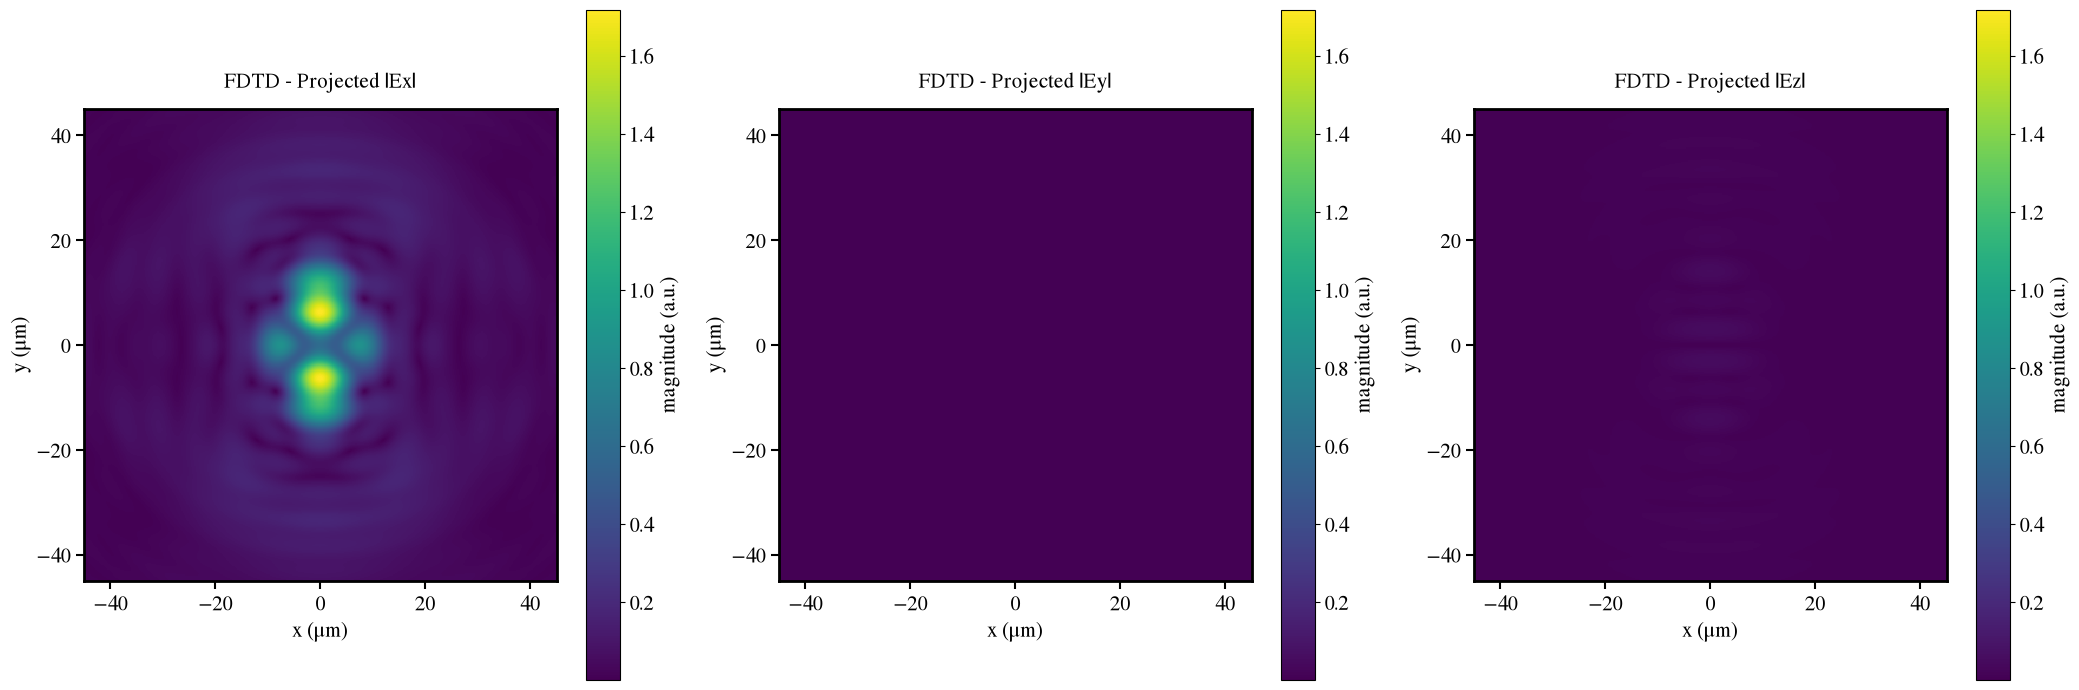

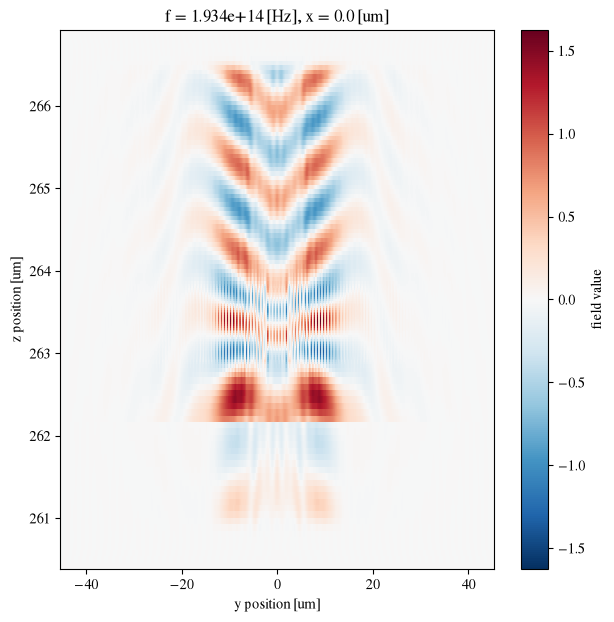

In [31]:
sim_data_2 = SimulationData.from_file(fname=f"full_meta_results/full_meta2_R_{using_radius_value}_{strategy}.hdf5")

forward_flux_2 = sim_data_2['transmittance_flux_monitor_2'].flux
backward_flux_2 = sim_data_2['reflectance_flux_monitor_2'].flux * (-1)

fig, ax = plt.subplots()
forward_flux_2.plot(ax=ax, x='f', label='T', color='b', linewidth=2)
backward_flux_2.plot(ax=ax, x='f', label='R', color='r', linewidth=2)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Flux")
ax.legend()
plt.tight_layout()
plt.show()
plt.close()

proj_fields_2 = sim_data_2["ff_proj_monitor_2"].fields_cartesian
with open(f"full_meta_results/proj_fields_sim2_R_{using_radius_value}_{strategy}.pkl", "wb") as f:
    pickle.dump(proj_fields_2, f)

proj_Ex_field_2 = proj_fields_2.Ex.sel(f=freq0, z=output_plane_position - projection_start_position_2)
proj_Ey_field_2 = proj_fields_2.Ey.sel(f=freq0, z=output_plane_position - projection_start_position_2)
proj_Ez_field_2 = proj_fields_2.Ez.sel(f=freq0, z=output_plane_position - projection_start_position_2)

fig, ax = plt.subplots(1,2,figsize=(14, 7))
np.abs(proj_Ex_field_2).plot(ax=ax[0], x = 'x', y = 'y', rasterized = True)

phase_Ex_field_2 = proj_Ex_field_2.copy(
    data=np.mod(np.angle(proj_Ex_field_2.data), 2 * np.pi)
)
phase_Ex_field_2.plot(ax=ax[1], x = 'x', y = 'y', cmap='hsv', rasterized = True)
#add a red circle to evidence the position of the fiber core
ax[0]
ax[0].set_title("")
ax[0].set_xlabel("x (μm)", fontsize=15)
ax[0].set_ylabel("y (μm)", fontsize=15)
ax[1].set_title("")
ax[1].set_xlabel("x (μm)", fontsize=15)
ax[1].set_ylabel("y (μm)", fontsize=15)
for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
ax[0].set_aspect('auto')
ax[1].set_aspect('auto')
plt.tight_layout()
plt.savefig(f"full_meta_results/plots/full_meta2_proj_fields_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)
plt.close()
#change the following plots to display the quantities on the same scale as the Ex component
fig, ax = plt.subplots(1,3,figsize=(21, 7))
im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_2), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_2).max(), vmin = np.abs(proj_Ex_field_2).min())
ax[0].set_title("FDTD - Projected |Ex|", fontsize=15, pad=15)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="magnitude (a.u.)")
cbar0.set_label("magnitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, np.abs(proj_Ey_field_2), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_2).max(), vmin = np.abs(proj_Ex_field_2).min())
ax[1].set_title("FDTD - Projected |Ey|", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="magnitude (a.u.)")
cbar1.set_label("magnitude (a.u.)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

im2 = ax[2].pcolormesh(X_far, Y_far, np.abs(proj_Ez_field_2), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_2).max(), vmin = np.abs(proj_Ex_field_2).min())
ax[2].set_title("FDTD - Projected |Ez|", fontsize=15, pad=15)
ax[2].set_xlabel("x (μm)", fontsize=15,)
ax[2].set_ylabel("y (μm)", fontsize=15,)
ax[2].set_aspect('equal')
cbar2 = plt.colorbar(im2, ax=ax[2], label="magnitude (a.u.)")
cbar2.set_label("magnitude (a.u.)", fontsize=15)
cbar2.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.title.set_fontsize(15)
    ax_item.xaxis.label.set_fontsize(15)
    ax_item.yaxis.label.set_fontsize(15)
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(2.0)
plt.tight_layout()
plt.show()
plt.close()
#plt.savefig(f"full_meta_results/full_meta2_proj_E_field_intensity_R_{using_radius_value}_{strategy}.pdf", bbox_inches='tight', dpi=300)

#plot the flux to observe source directionality
#add a red line at the source position
fig, ax = plt.subplots(1)
sim_data_2["field_yz_2"].Ex.sel(f=[freq0], x=0).real.plot(ax=ax, y = 'z')

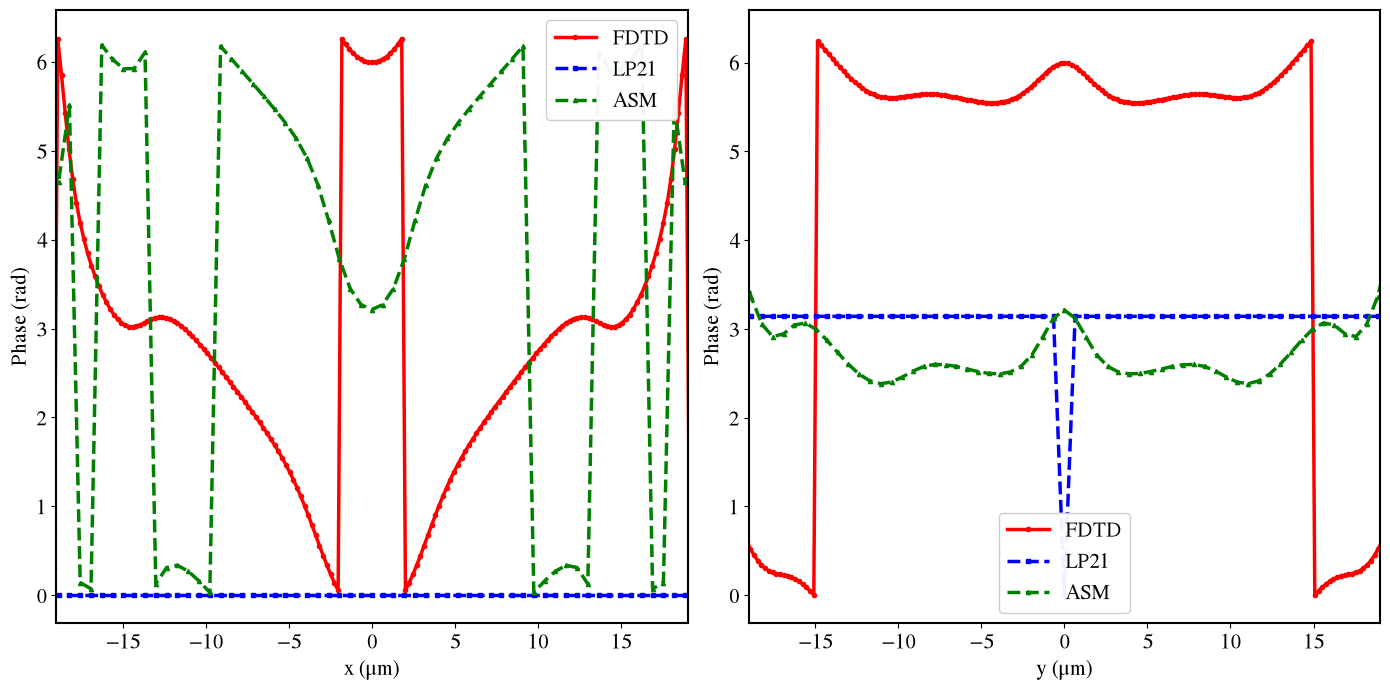

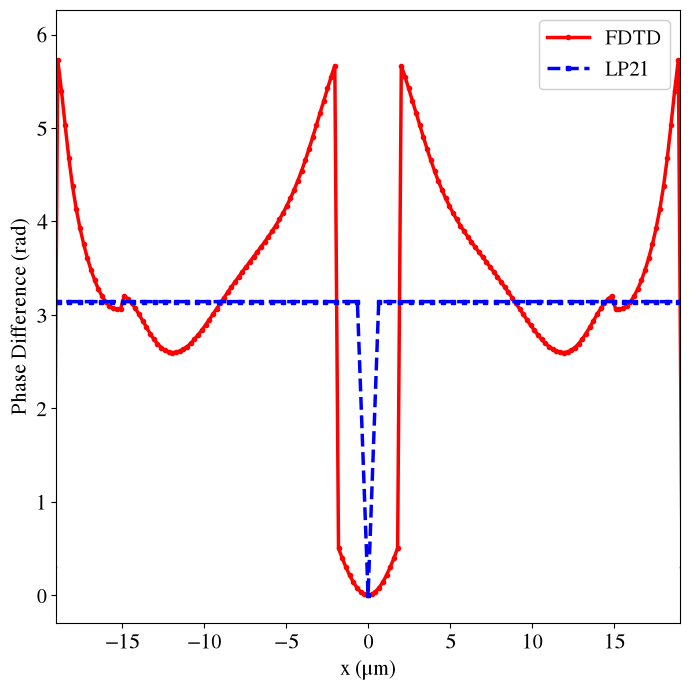

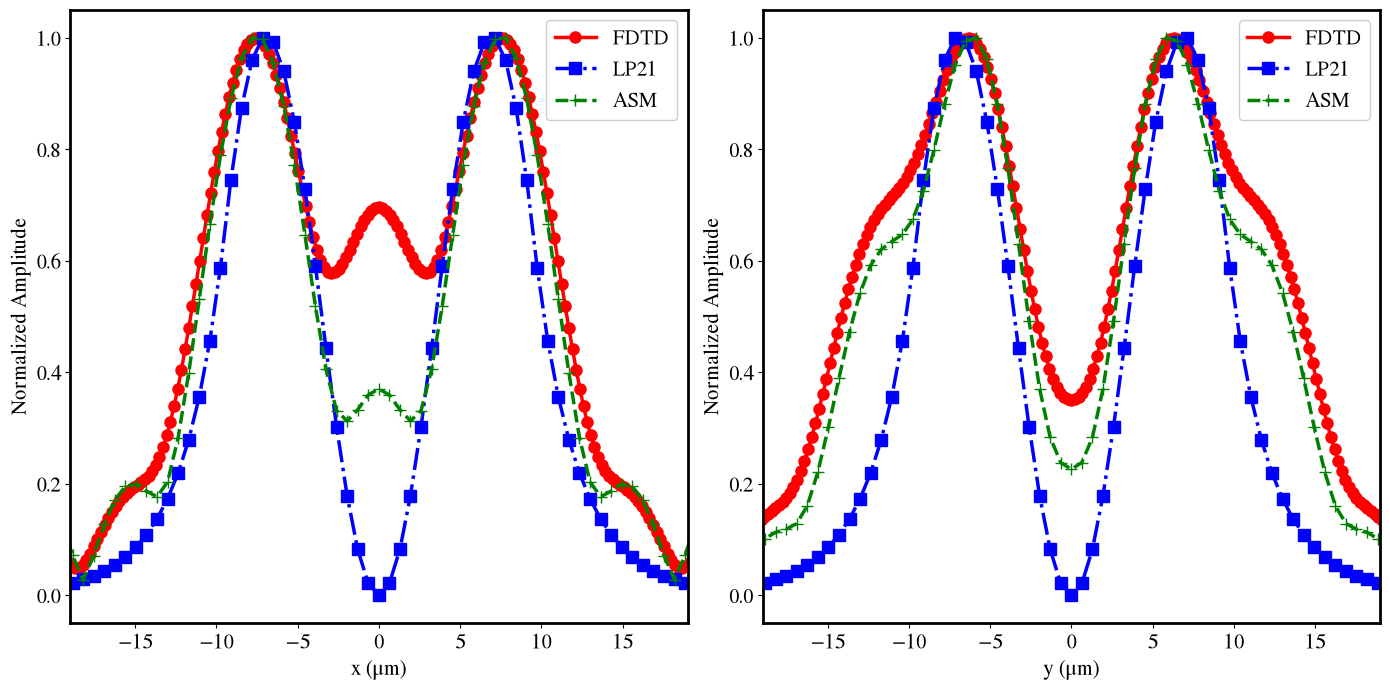

In [32]:
#import asm field
asm_output_field = np.load(f"../results_radius_{using_radius_value}_{strategy}/output_field_1_55.npy")
asm_output_field_slice_xCut = asm_output_field.reshape(X.shape[0], X.shape[1])[X.shape[0]//2, :]
asm_output_field_slice_yCut = asm_output_field.reshape(X.shape[0], X.shape[1])[:, X.shape[1]//2]
#import target output fields
target_output_field = np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1550_N_1025.npy")
output_fiber_core_diameter = 19
#make a 1D slice to compare phase of projected and target fields
#phase
projected_field_MS2_slice_x = proj_fields_2.x
projected_field_MS2_slice_xCut = proj_Ex_field_2[X_far.shape[0]//2, :]
projected_field_MS2_slice_y = proj_fields_2.y
projected_field_MS2_slice_yCut = proj_Ex_field_2[:,Y_far.shape[0]//2]

target_output_field_slice_xCut = target_output_field[X.shape[0]//2,:]
target_output_field_slice_x = X[X.shape[0]//2,:]
target_output_field_slice_yCut = target_output_field[:,Y.shape[0]//2]
target_output_field_slice_y = Y[:,Y.shape[0]//2]

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(projected_field_MS2_slice_x, (np.angle(projected_field_MS2_slice_xCut)+2*np.pi)%(2*np.pi),
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax[0].plot(target_output_field_slice_x, (np.angle(target_output_field_slice_xCut)+2*np.pi)%(2*np.pi),
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax[0].plot(target_output_field_slice_x, (np.angle(asm_output_field_slice_xCut)+2*np.pi)%(2*np.pi),
           '--g', label="ASM", linewidth=2.5, marker='^', markersize=3,)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("Phase (rad)", fontsize=15,)
ax[0].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[0].tick_params(labelsize=15)
ax[0].legend(fontsize=15, loc='best', framealpha=0.95)


ax[1].plot(projected_field_MS2_slice_y, (np.angle(projected_field_MS2_slice_yCut)+2*np.pi)%(2*np.pi),
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax[1].plot(target_output_field_slice_y, (np.angle(target_output_field_slice_yCut)+2*np.pi)%(2*np.pi),
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax[1].plot(target_output_field_slice_y, (np.angle(asm_output_field_slice_yCut)+2*np.pi)%(2*np.pi),
           '--g', label="ASM", linewidth=2.5, marker='^', markersize=3,)
ax[1].set_xlabel("y (μm)", fontsize=15,)
ax[1].set_ylabel("Phase (rad)", fontsize=15,)
ax[1].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[1].tick_params(labelsize=15)
ax[1].legend(fontsize=15, loc='best', framealpha=0.95)


for ax_item in ax:
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()
#plt.savefig(f"full_meta_results/fdtd_vs-target_output_field_phase_R_{using_radius_value}_{strategy}.pdf")
plt.close()

#relative phase difference between x and y spatial slices for both FDTD and target fields
fig, ax = plt.subplots(figsize=(7, 7))
fdtd_phase_diff = np.abs((np.angle(projected_field_MS2_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(projected_field_MS2_slice_yCut)+2*np.pi)%(2*np.pi))
target_phase_diff = np.abs((np.angle(target_output_field_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(target_output_field_slice_yCut)+2*np.pi)%(2*np.pi))
ax.plot(projected_field_MS2_slice_x, fdtd_phase_diff,
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax.plot(target_output_field_slice_x, target_phase_diff,
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax.set_xlabel("x (μm)", fontsize=15,)
ax.set_ylabel("Phase Difference (rad)", fontsize=15,)
ax.set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax.tick_params(labelsize=15)
ax.legend(fontsize=15, loc='best', framealpha=0.95)
plt.tight_layout()
plt.show()
#plt.savefig(f"full_meta_results/differential_output_field_phase_R_{using_radius_value}_{strategy}.pdf")
plt.close()

#amplitudes
normalized_projected_field_MS2_xCut = np.abs(projected_field_MS2_slice_xCut) / np.max(np.abs(projected_field_MS2_slice_xCut))
normalized_target_output_field_xCut = np.abs(target_output_field_slice_xCut) / np.max(np.abs(target_output_field_slice_xCut))
normalized_projected_field_MS2_yCut = np.abs(projected_field_MS2_slice_yCut) / np.max(np.abs(projected_field_MS2_slice_yCut))
normalized_target_output_field_yCut = np.abs(target_output_field_slice_yCut) / np.max(np.abs(target_output_field_slice_yCut))

normalized_asm_output_field_xCut = np.abs(asm_output_field_slice_xCut) / np.max(np.abs(asm_output_field_slice_xCut))
normalized_asm_output_field_yCut = np.abs(asm_output_field_slice_yCut) / np.max(np.abs(asm_output_field_slice_yCut))

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(projected_field_MS2_slice_x, normalized_projected_field_MS2_xCut,
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=8,)
ax[0].plot(target_output_field_slice_x, normalized_target_output_field_xCut,
           '-.b', label="LP21", linewidth=2.5, marker='s', markersize=8,)
ax[0].plot(target_output_field_slice_x, normalized_asm_output_field_xCut,
           '--g', label="ASM", linewidth=2.5, marker='+', markersize=8,)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("Normalized Amplitude", fontsize=15,)
ax[0].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[0].tick_params(labelsize=15)
ax[0].legend(fontsize=15, loc='best', framealpha=0.95)


ax[1].plot(projected_field_MS2_slice_y, normalized_projected_field_MS2_yCut,
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=8,)
ax[1].plot(target_output_field_slice_y, normalized_target_output_field_yCut,
           '-.b', label="LP21", linewidth=2.5, marker='s', markersize=8,)
ax[1].plot(target_output_field_slice_y, normalized_asm_output_field_yCut,
           '--g', label="ASM", linewidth=2.5, marker='+', markersize=8,)
ax[1].set_xlabel("y (μm)", fontsize=15,)
ax[1].set_ylabel("Normalized Amplitude", fontsize=15,)
ax[1].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[1].tick_params(labelsize=15)
ax[1].legend(fontsize=15, loc='best', framealpha=0.95)


for ax_item in ax:
    for spine in ax_item.spines.values():
        spine.set_linewidth(2.0)

plt.tight_layout()
plt.show()
#plt.savefig(f"full_meta_results/fdtd_vs_target_output_field_normalized_amplitude_R_{using_radius_value}_{strategy}.pdf")

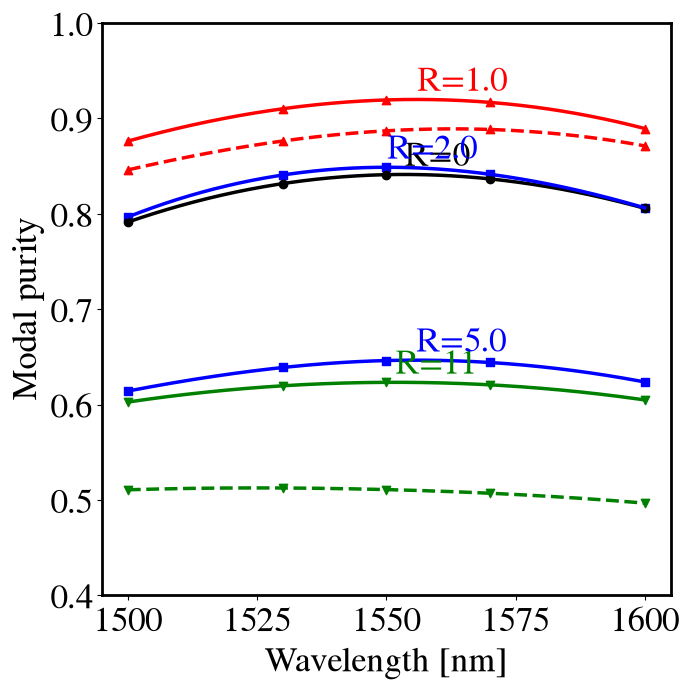

In [37]:
#let's compute the overlap integral between the target field and the synthetized output
#first step: define the target field using a FieldData object
lda0 = 1.55
lambda0 = lda0
freq0 = td.C_0 / lda0

action = 'epigraph'
#load the output field from simulation for both epigraph and mean strategies
#epigraph strategy
if action == 'epigraph' or action == 'both':
    #radius 1_0
    with open(f"full_meta_results/proj_fields_sim2_R_1_0_epigraph.pkl", "rb") as f:
        proj_fields_sim2_epigraph_1_0 = pickle.load(f)
    #radius 11_0
    with open(f"full_meta_results/proj_fields_sim2_R_11_0_epigraph.pkl", "rb") as f:
        proj_fields_sim2_epigraph_11 = pickle.load(f)
#mean strategy
if action == 'mean' or action == 'both':
    #filter radius 1
    with open(f"full_meta_results/proj_fields_sim2_R_1_0_mean.pkl", "rb") as f:
        proj_fields_sim2_mean_1_0 = pickle.load(f)

#select the only z available in the output field
if action == 'mean' or action == 'both':
    output_field_Ex_fdtd_mean_1_0 = proj_fields_sim2_mean_1_0.Ex.sel(z=proj_fields_sim2_mean_1_0.z.values[0])
if action == 'epigraph' or action == 'both':
    output_field_Ex_fdtd_epigraph_1_0 = proj_fields_sim2_epigraph_1_0.Ex.sel(z=proj_fields_sim2_epigraph_1_0.z.values[0])
    output_field_Ex_fdtd_epigraph_11 = proj_fields_sim2_epigraph_11.Ex.sel(z=proj_fields_sim2_epigraph_11.z.values[0])

#targets listed in ascending frequency order (long wavelength to short wavelength)
target_Ex_list = [np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1500_N_1025.npy"),
                  np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1530_N_1025.npy"),
                  np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1550_N_1025.npy"),
                  np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1570_N_1025.npy"),
                  np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1600_N_1025.npy")]

#ASM fields
if action == 'mean' or action == 'both':
    asm_Ex_list_mean_1_0 = [np.load(f"../results_radius_1_0_mean/output_field_1_5.npy"),
                np.load(f"../results_radius_1_0_mean/output_field_1_53.npy"),
                np.load(f"../results_radius_1_0_mean/output_field_1_55.npy"),
                np.load(f"../results_radius_1_0_mean/output_field_1_57.npy"),
                np.load(f"../results_radius_1_0_mean/output_field_1_6.npy"),]

if action == 'epigraph' or action == 'both':
    #radius NO-FILTER (0)
    asm_Ex_list_epigraph_0 = [np.load(f"../results_radius_0_epigraph/output_field_1_5.npy"),
                np.load(f"../results_radius_0_epigraph/output_field_1_53.npy"),
                np.load(f"../results_radius_0_epigraph/output_field_1_55.npy"),
                np.load(f"../results_radius_0_epigraph/output_field_1_57.npy"),
                np.load(f"../results_radius_0_epigraph/output_field_1_6.npy"),]

    #radius 1_0
    asm_Ex_list_epigraph_1_0 = [np.load(f"../results_radius_1_0_epigraph/output_field_1_5.npy"),
                np.load(f"../results_radius_1_0_epigraph/output_field_1_53.npy"),
                np.load(f"../results_radius_1_0_epigraph/output_field_1_55.npy"),
                np.load(f"../results_radius_1_0_epigraph/output_field_1_57.npy"),
                np.load(f"../results_radius_1_0_epigraph/output_field_1_6.npy"),]
    
    #radius 2_0
    asm_Ex_list_epigraph_2_0 = [np.load(f"../results_radius_2_0_epigraph/output_field_1_5.npy"),
                np.load(f"../results_radius_2_0_epigraph/output_field_1_53.npy"),
                np.load(f"../results_radius_2_0_epigraph/output_field_1_55.npy"),
                np.load(f"../results_radius_2_0_epigraph/output_field_1_57.npy"),
                np.load(f"../results_radius_2_0_epigraph/output_field_1_6.npy"),]
    
    #radius 5_0
    asm_Ex_list_epigraph_5_0 = [np.load(f"../results_radius_5_0_epigraph/output_field_1_5.npy"),
                np.load(f"../results_radius_5_0_epigraph/output_field_1_53.npy"),
                np.load(f"../results_radius_5_0_epigraph/output_field_1_55.npy"),
                np.load(f"../results_radius_5_0_epigraph/output_field_1_57.npy"),
                np.load(f"../results_radius_5_0_epigraph/output_field_1_6.npy"),]
    
    #radius 11
    asm_Ex_list_epigraph_11 = [np.load(f"../results_radius_11_0_epigraph/output_field_1_5.npy"),
                np.load(f"../results_radius_11_0_epigraph/output_field_1_53.npy"),
                np.load(f"../results_radius_11_0_epigraph/output_field_1_55.npy"),
                np.load(f"../results_radius_11_0_epigraph/output_field_1_57.npy"),
                np.load(f"../results_radius_11_0_epigraph/output_field_1_6.npy"),]


def overlap_integral(target_E, output_E):
    overlap = np.abs(np.sum(output_E * np.conj(target_E))) ** 2
    modal_purity = overlap / (np.sum(np.abs(output_E) ** 2) * np.sum(np.abs(target_E) ** 2))
    return modal_purity

#interpolation is needed to downscale the target field to match the output field's grid
from scipy.interpolate import RegularGridInterpolator

#for all the frequencies, compute the overalap
overlap_results_list_fdtd_mean_1_0 = []
overlap_results_list_fdtd_epigraph_1_0 = []
overlap_results_list_fdtd_epigraph_11 = []

overlap_results_list_asm_epigraph_0 = []
overlap_results_list_asm_mean_1_0 = []
overlap_results_list_asm_epigraph_1_0 = []
overlap_results_list_asm_epigraph_2_0 = []
overlap_results_list_asm_epigraph_5_0 = []
overlap_results_list_asm_epigraph_11 = []
#generate a new pair of X and Y matrices that only contain the spatial coordinates of X_far and Y_far, if outside, replace with 0
X_clip_mask = np.where((X >= xs_far.min()) & (X <= xs_far.max()), 1, 0)
Y_clip_mask = np.where((Y >= ys_far.min()) & (Y <= ys_far.max()), 1, 0)
X_clip = X * X_clip_mask
Y_clip = Y * Y_clip_mask


for i, freq in enumerate(freq_list):
    target_Ex = target_Ex_list[i]
    if action == 'mean' or action == 'both':
        asm_Ex_mean_1_0 = asm_Ex_list_mean_1_0[i].reshape(X.shape[0], X.shape[1])
        asm_Ex_mean_1_0 = asm_Ex_mean_1_0 * X_clip_mask
    if action == 'epigraph' or action == 'both':
        asm_Ex_epigraph_1_0 = asm_Ex_list_epigraph_1_0[i].reshape(X.shape[0], X.shape[1])
        asm_Ex_epigraph_1_0 = asm_Ex_epigraph_1_0 * X_clip_mask
        asm_Ex_epigraph_2_0 = asm_Ex_list_epigraph_2_0[i].reshape(X.shape[0], X.shape[1])
        asm_Ex_epigraph_2_0 = asm_Ex_epigraph_2_0 * X_clip_mask
        asm_Ex_epigraph_5_0 = asm_Ex_list_epigraph_5_0[i].reshape(X.shape[0], X.shape[1])
        asm_Ex_epigraph_5_0 = asm_Ex_epigraph_5_0 * X_clip_mask
        asm_Ex_epigraph_11 = asm_Ex_list_epigraph_11[i].reshape(X.shape[0], X.shape[1])
        asm_Ex_epigraph_11 = asm_Ex_epigraph_11 * X_clip_mask
        asm_Ex_epigraph_0 = asm_Ex_list_epigraph_0[i].reshape(X.shape[0], X.shape[1])
        asm_Ex_epigraph_0 = asm_Ex_epigraph_0 * X_clip_mask
    
    if action == 'mean' or action == 'both':
        computed_overlap_asm_mean_1_0 = overlap_integral(target_Ex, asm_Ex_mean_1_0)
        overlap_results_list_asm_mean_1_0.append(computed_overlap_asm_mean_1_0)
    if action == 'epigraph' or action == 'both':
        computed_overlap_asm_epigraph_1_0 = overlap_integral(target_Ex, asm_Ex_epigraph_1_0)
        overlap_results_list_asm_epigraph_1_0.append(computed_overlap_asm_epigraph_1_0)
        computed_overlap_asm_epigraph_11 = overlap_integral(target_Ex, asm_Ex_epigraph_11)
        overlap_results_list_asm_epigraph_11.append(computed_overlap_asm_epigraph_11)
        computed_overlap_asm_epigraph_2_0 = overlap_integral(target_Ex, asm_Ex_epigraph_2_0)
        overlap_results_list_asm_epigraph_2_0.append(computed_overlap_asm_epigraph_2_0)
        computed_overlap_asm_epigraph_5_0 = overlap_integral(target_Ex, asm_Ex_epigraph_5_0)
        overlap_results_list_asm_epigraph_5_0.append(computed_overlap_asm_epigraph_5_0)
        computed_overlap_asm_epigraph_0 = overlap_integral(target_Ex, asm_Ex_epigraph_0)
        overlap_results_list_asm_epigraph_0.append(computed_overlap_asm_epigraph_0)
        
    
    # Extract FDTD field for the selected frequency (freq)
    if action == 'mean' or action == 'both':
        output_Ex_fdtd_2d_mean_1_0 = output_field_Ex_fdtd_mean_1_0.sel(f=freq).data
    if action == 'epigraph' or action == 'both':
        output_Ex_fdtd_2d_epigraph_1_0 = output_field_Ex_fdtd_epigraph_1_0.sel(f=freq).data
        output_Ex_fdtd_2d_epigraph_11 = output_field_Ex_fdtd_epigraph_11.sel(f=freq).data
    
    # Create interpolator for FDTD using its native coordinates (xs_far, ys_far)
    if action == 'mean' or action == 'both':
        fdtd_interpolator_mean = RegularGridInterpolator(
            (xs_far, ys_far), 
            output_Ex_fdtd_2d_mean_1_0, 
            method='linear', 
            bounds_error=False, 
            fill_value=0.0 
        )
    if action == 'epigraph' or action == 'both':
        fdtd_interpolator_epigraph_1_0 = RegularGridInterpolator(
            (xs_far, ys_far), 
            output_Ex_fdtd_2d_epigraph_1_0, 
            method='linear', 
            bounds_error=False, 
            fill_value=0.0 
        )

        fdtd_interpolator_epigraph_11 = RegularGridInterpolator(
            (xs_far, ys_far), 
            output_Ex_fdtd_2d_epigraph_11, 
            method='linear', 
            bounds_error=False, 
            fill_value=0.0 
        )

    # Evaluate FDTD field on target/ASM coordinate grid (X, Y)
    eval_points = np.column_stack([X.ravel(), Y.ravel()])
    if action == 'mean' or action == 'both':
        output_Ex_fdtd_on_asm_grid_mean_1_0 = fdtd_interpolator_mean(eval_points).reshape(X.shape)
    if action == 'epigraph' or action == 'both':
        output_Ex_fdtd_on_asm_grid_epigraph_1_0 = fdtd_interpolator_epigraph_1_0(eval_points).reshape(X.shape)
        output_Ex_fdtd_on_asm_grid_epigraph_11 = fdtd_interpolator_epigraph_11(eval_points).reshape(X.shape)

    # Compute FDTD overlap using the same target field and shared grid
    if action == 'mean' or action == 'both':
        computed_overlap_fdtd_mean_1_0 = overlap_integral(target_Ex, output_Ex_fdtd_on_asm_grid_mean_1_0)
        overlap_results_list_fdtd_mean_1_0.append(computed_overlap_fdtd_mean_1_0)
    if action == 'epigraph' or action == 'both':
        computed_overlap_fdtd_epigraph_1_0 = overlap_integral(target_Ex, output_Ex_fdtd_on_asm_grid_epigraph_1_0)
        overlap_results_list_fdtd_epigraph_1_0.append(computed_overlap_fdtd_epigraph_1_0)
        computed_overlap_fdtd_epigraph_11 = overlap_integral(target_Ex, output_Ex_fdtd_on_asm_grid_epigraph_11)
        overlap_results_list_fdtd_epigraph_11.append(computed_overlap_fdtd_epigraph_11)


#make a cubic spline interpolation of the results
from scipy.interpolate import CubicSpline
if action == 'mean' or action == 'both':
    overlap_results_list_asm_mean_1_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_asm_mean_1_0)
    overlap_results_list_fdtd_mean_1_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_fdtd_mean_1_0)
if action == 'epigraph' or action == 'both':
    overlap_results_list_asm_epigraph_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_asm_epigraph_0)
    overlap_results_list_asm_epigraph_1_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_asm_epigraph_1_0)
    overlap_results_list_fdtd_epigraph_1_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_fdtd_epigraph_1_0)
    overlap_results_list_asm_epigraph_2_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_asm_epigraph_2_0)
    overlap_results_list_asm_epigraph_5_0_spline = CubicSpline(lda_list*1e3, overlap_results_list_asm_epigraph_5_0)
    overlap_results_list_asm_epigraph_11_spline = CubicSpline(lda_list*1e3, overlap_results_list_asm_epigraph_11)
    overlap_results_list_fdtd_epigraph_11_spline = CubicSpline(lda_list*1e3, overlap_results_list_fdtd_epigraph_11)

fine_lda_list = np.linspace(min(lda_list*1e3), max(lda_list*1e3), 500)

#make a simple plot of the overlap results
#instead of the legend, add a text box near the plot of interest with the text: R=<radius> near the 
#position of the maximum value data point and with the same color used for the plot
fig, ax = plt.subplots()
if action == 'mean' or action == 'both':
    ax.scatter(lda_list*1e3, overlap_results_list_asm_mean_1_0, marker='+', c='r')
    ax.scatter(lda_list*1e3, overlap_results_list_fdtd_mean_1_0, marker='+', c='r')
if action == 'epigraph' or action == 'both':
    ax.scatter(lda_list*1e3, overlap_results_list_asm_epigraph_1_0, marker='^', c='r')
    ax.scatter(lda_list*1e3, overlap_results_list_fdtd_epigraph_1_0, marker='^', c='r')
    ax.scatter(lda_list*1e3, overlap_results_list_asm_epigraph_11, marker='v', c='g')
    ax.scatter(lda_list*1e3, overlap_results_list_fdtd_epigraph_11, marker='v', c='g')
    ax.scatter(lda_list*1e3, overlap_results_list_asm_epigraph_2_0, marker='s', c='b')
    ax.scatter(lda_list*1e3, overlap_results_list_asm_epigraph_5_0, marker='s', c='b')
    ax.scatter(lda_list*1e3, overlap_results_list_asm_epigraph_0, marker='o', c='k')
if action == 'mean' or action == 'both':
    ax.plot(fine_lda_list, overlap_results_list_asm_mean_1_0_spline(fine_lda_list), c='orange', linewidth=2.5, linestyle='-', label='ASM Mean - R=1.0')
    ax.plot(fine_lda_list, overlap_results_list_fdtd_mean_1_0_spline(fine_lda_list),c='orange', linewidth=2.5, linestyle='-.', label='FDTD Mean - R=1.0')
if action == 'epigraph' or action == 'both':
    ax.plot(fine_lda_list, overlap_results_list_asm_epigraph_0_spline(fine_lda_list), c='k', linewidth=2.5, label='ASM Epigraph - R=0')
    ax.text(fine_lda_list[np.argmax(overlap_results_list_asm_epigraph_0_spline(fine_lda_list))],
            max(overlap_results_list_asm_epigraph_0_spline(fine_lda_list)),
            'R=0', color='k', fontsize=25, verticalalignment='bottom', horizontalalignment='left')
    ax.plot(fine_lda_list, overlap_results_list_asm_epigraph_1_0_spline(fine_lda_list), c='r', linewidth=2.5, label='ASM Epigraph - R=1.0')
    ax.text(fine_lda_list[np.argmax(overlap_results_list_asm_epigraph_1_0_spline(fine_lda_list))],
            max(overlap_results_list_asm_epigraph_1_0_spline(fine_lda_list)),
            'R=1.0', color='r', fontsize=25, verticalalignment='bottom', horizontalalignment='left')
    ax.plot(fine_lda_list, overlap_results_list_fdtd_epigraph_1_0_spline(fine_lda_list),c='r', linewidth=2.5, linestyle='--', label='FDTD Epigraph - R=1.0')
    ax.plot(fine_lda_list, overlap_results_list_asm_epigraph_11_spline(fine_lda_list), c='g', linewidth=2.5, label='ASM Epigraph - R=11')
    ax.text(fine_lda_list[np.argmax(overlap_results_list_asm_epigraph_11_spline(fine_lda_list))],
            max(overlap_results_list_asm_epigraph_11_spline(fine_lda_list)),
            'R=11', color='g', fontsize=25, verticalalignment='bottom', horizontalalignment='left')
    ax.plot(fine_lda_list, overlap_results_list_fdtd_epigraph_11_spline(fine_lda_list),c='g', linewidth=2.5, linestyle='--', label='FDTD Epigraph - R=11')
    ax.plot(fine_lda_list, overlap_results_list_asm_epigraph_2_0_spline(fine_lda_list), c='b', linewidth=2.5, label='ASM Epigraph - R=2.0')
    ax.text(fine_lda_list[np.argmax(overlap_results_list_asm_epigraph_2_0_spline(fine_lda_list))],
            max(overlap_results_list_asm_epigraph_2_0_spline(fine_lda_list)),
            'R=2.0', color='b', fontsize=25, verticalalignment='bottom', horizontalalignment='left')
    ax.plot(fine_lda_list, overlap_results_list_asm_epigraph_5_0_spline(fine_lda_list), c='b', linewidth=2.5, label='ASM Epigraph - R=5.0')
    ax.text(fine_lda_list[np.argmax(overlap_results_list_asm_epigraph_5_0_spline(fine_lda_list))],
            max(overlap_results_list_asm_epigraph_5_0_spline(fine_lda_list)),
            'R=5.0', color='b', fontsize=25, verticalalignment='bottom', horizontalalignment='left')
    
ax.set_ylim(0.4,1)
ax.set_xlabel("Wavelength [nm]", fontsize=25)
ax.set_ylabel("Modal purity", fontsize=25)
ax.tick_params(axis='both', which='major', labelsize=25)
#set the thickness of the spines
for spine in ax.spines.values():
    spine.set_linewidth(2)

plt.tight_layout()
plt.savefig("full_meta_results/modal_purity_comparison.pdf")
#plt.close()
#DASHED CURVES: FDTD results
#SOLID CURVES: ASM results

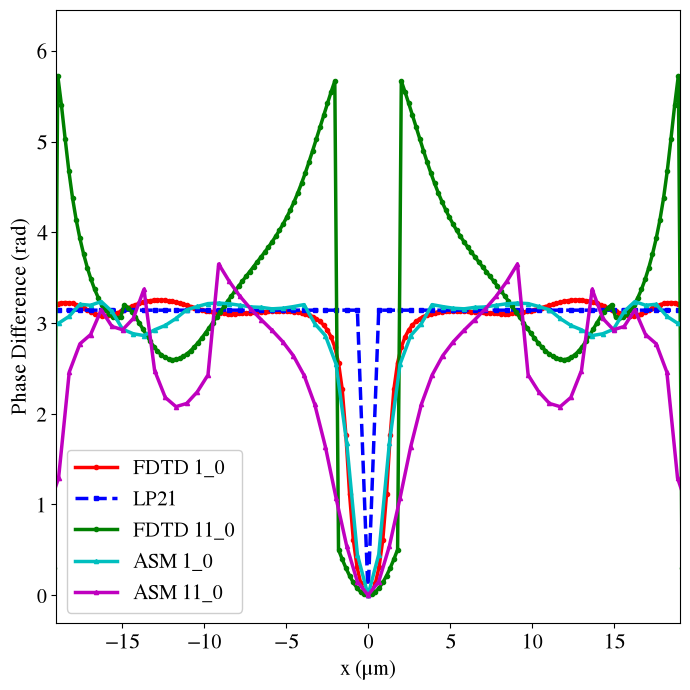

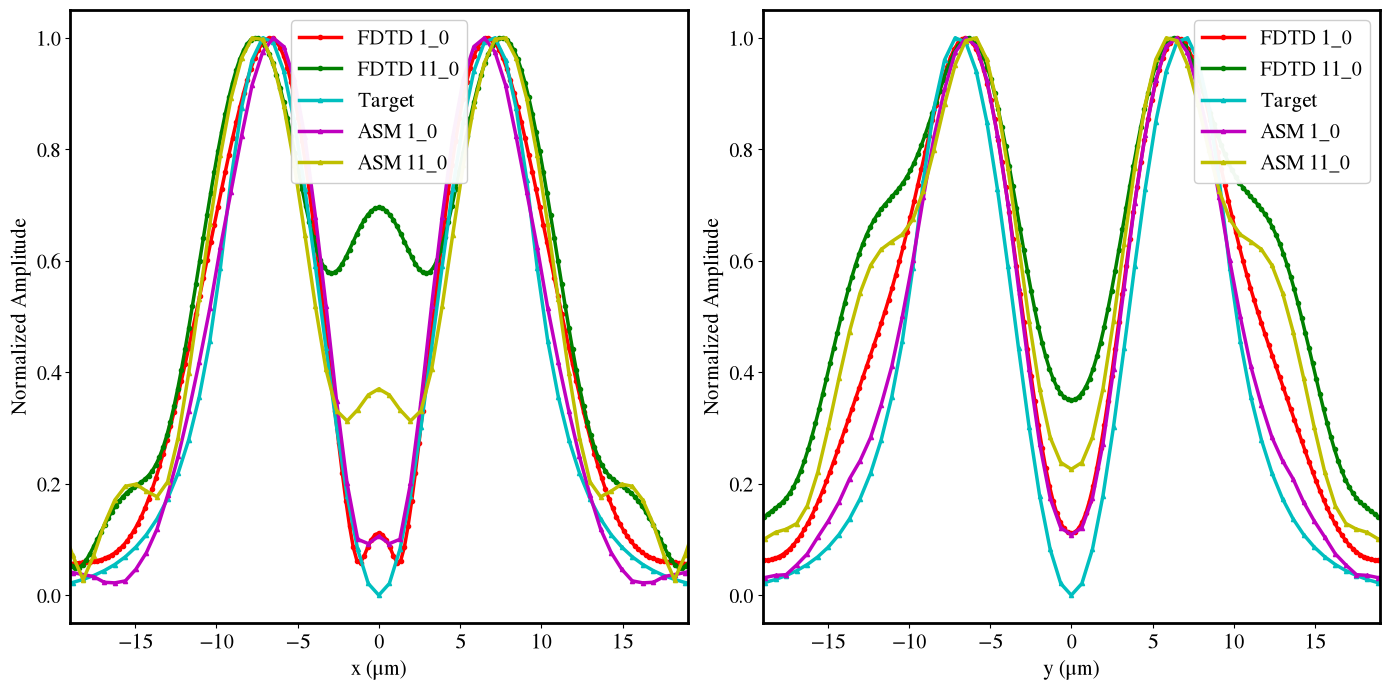

In [34]:
#import asm field
asm_output_field_1_0_epigraph = np.load(f"../results_radius_1_0_epigraph/output_field_1_55.npy")
asm_output_field_11_0_epigraph = np.load(f"../results_radius_11_0_epigraph/output_field_1_55.npy")

asm_output_field_1_0_epigraph_slice_xCut = asm_output_field_1_0_epigraph.reshape(X.shape[0], X.shape[1])[X.shape[0]//2, :]
asm_output_field_1_0_epigraph_slice_yCut = asm_output_field_1_0_epigraph.reshape(X.shape[0], X.shape[1])[:, X.shape[1]//2]
asm_output_field_11_0_epigraph_slice_xCut = asm_output_field_11_0_epigraph.reshape(X.shape[0], X.shape[1])[X.shape[0]//2, :]
asm_output_field_11_0_epigraph_slice_yCut = asm_output_field_11_0_epigraph.reshape(X.shape[0], X.shape[1])[:, X.shape[1]//2]
#import target output fields
target_output_field = np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1550_N_1025.npy")
output_fiber_core_diameter = 19

#load FDTD fields from saved pickle files
with open(f"full_meta_results/proj_fields_sim2_R_1_0_epigraph.pkl", "rb") as f:
    proj_fields_2_1_0_epigraph = pickle.load(f)
#select the operating frequency to be freq0
proj_fields_2_1_0_epigraph = proj_fields_2_1_0_epigraph.sel(f=freq0)
with open(f"full_meta_results/proj_fields_sim2_R_11_0_epigraph.pkl", "rb") as f:
    proj_fields_2_11_0_epigraph = pickle.load(f)
proj_fields_2_11_0_epigraph = proj_fields_2_11_0_epigraph.sel(f=freq0)


projected_field_MS2_slice_x_1_0_epigraph = proj_fields_2_1_0_epigraph.x.values
projected_field_MS2_slice_y_1_0_epigraph = proj_fields_2_1_0_epigraph.y.values
projected_field_MS2_slice_x_11_0_epigraph = proj_fields_2_11_0_epigraph.x.values
projected_field_MS2_slice_y_11_0_epigraph = proj_fields_2_11_0_epigraph.y.values

projected_field_MS2_slice_xCut_1_0_epigraph = proj_fields_2_1_0_epigraph.Ex[X_far.shape[0]//2, :]
projected_field_MS2_slice_xCut_11_0_epigraph = proj_fields_2_11_0_epigraph.Ex[X_far.shape[0]//2, :]

projected_field_MS2_slice_yCut_1_0_epigraph = proj_fields_2_1_0_epigraph.Ex[:,Y_far.shape[0]//2]
projected_field_MS2_slice_yCut_11_0_epigraph = proj_fields_2_11_0_epigraph.Ex[:,Y_far.shape[0]//2]

target_output_field_slice_xCut = target_output_field[X.shape[0]//2,:]
target_output_field_slice_x = X[X.shape[0]//2,:]
target_output_field_slice_yCut = target_output_field[:,Y.shape[0]//2]
target_output_field_slice_y = Y[:,Y.shape[0]//2]

#relative phase difference between x and y spatial slices for both FDTD and target fields
fig, ax = plt.subplots(figsize=(7, 7))

fdtd_phase_diff_1_0_epigraph = np.abs((np.angle(projected_field_MS2_slice_xCut_1_0_epigraph)+2*np.pi)%(2*np.pi) - (np.angle(projected_field_MS2_slice_yCut_1_0_epigraph)+2*np.pi)%(2*np.pi))
fdtd_phase_diff_11_0_epigraph = np.abs((np.angle(projected_field_MS2_slice_xCut_11_0_epigraph)+2*np.pi)%(2*np.pi) - (np.angle(projected_field_MS2_slice_yCut_11_0_epigraph)+2*np.pi)%(2*np.pi))
asm_phase_diff_1_0_epigraph = np.abs((np.angle(asm_output_field_1_0_epigraph_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(asm_output_field_1_0_epigraph_slice_yCut)+2*np.pi)%(2*np.pi))
asm_phase_diff_11_0_epigraph = np.abs((np.angle(asm_output_field_11_0_epigraph_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(asm_output_field_11_0_epigraph_slice_yCut)+2*np.pi)%(2*np.pi))
target_phase_diff = np.abs((np.angle(target_output_field_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(target_output_field_slice_yCut)+2*np.pi)%(2*np.pi))

ax.plot(projected_field_MS2_slice_x_1_0_epigraph, fdtd_phase_diff_1_0_epigraph,
           'r', label="FDTD 1_0", linewidth=2.5, marker='o', markersize=3,)
ax.plot(target_output_field_slice_x, target_phase_diff,
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax.plot(projected_field_MS2_slice_x_11_0_epigraph, fdtd_phase_diff_11_0_epigraph,
           'g', label="FDTD 11_0", linewidth=2.5, marker='o', markersize=3,)
ax.plot(target_output_field_slice_x, asm_phase_diff_1_0_epigraph,
           'c', label="ASM 1_0", linewidth=2.5, marker='^', markersize=3,)
ax.plot(target_output_field_slice_x, asm_phase_diff_11_0_epigraph,
           'm', label="ASM 11_0", linewidth=2.5, marker='^', markersize=3,)
ax.set_xlabel("x (μm)", fontsize=15,)
ax.set_ylabel("Phase Difference (rad)", fontsize=15,)
ax.set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax.tick_params(labelsize=15)
ax.legend(fontsize=15, loc='best', framealpha=0.95)
plt.tight_layout()
plt.show()
#plt.savefig(f"full_meta_results/differential_output_field_phase_R_{using_radius_value}_{strategy}.pdf")
plt.close()

#amplitudes
normalized_ftdt_field_xCut_1_0_epigraph = np.abs(projected_field_MS2_slice_xCut_1_0_epigraph) / np.max(np.abs(projected_field_MS2_slice_xCut_1_0_epigraph))
normalized_ftdt_field_xCut_11_0_epigraph = np.abs(projected_field_MS2_slice_xCut_11_0_epigraph) / np.max(np.abs(projected_field_MS2_slice_xCut_11_0_epigraph))
normalized_ftdt_field_yCut_1_0_epigraph = np.abs(projected_field_MS2_slice_yCut_1_0_epigraph) / np.max(np.abs(projected_field_MS2_slice_yCut_1_0_epigraph))
normalized_ftdt_field_yCut_11_0_epigraph = np.abs(projected_field_MS2_slice_yCut_11_0_epigraph) / np.max(np.abs(projected_field_MS2_slice_yCut_11_0_epigraph))

normalized_target_output_field_xCut = np.abs(target_output_field_slice_xCut) / np.max(np.abs(target_output_field_slice_xCut))
normalized_target_output_field_yCut = np.abs(target_output_field_slice_yCut) / np.max(np.abs(target_output_field_slice_yCut))

normalized_asm_output_field_xCut_1_0_epigraph = np.abs(asm_output_field_1_0_epigraph_slice_xCut) / np.max(np.abs(asm_output_field_1_0_epigraph_slice_xCut))
normalized_asm_output_field_yCut_1_0_epigraph = np.abs(asm_output_field_1_0_epigraph_slice_yCut) / np.max(np.abs(asm_output_field_1_0_epigraph_slice_yCut))
normalized_asm_output_field_xCut_11_0_epigraph = np.abs(asm_output_field_11_0_epigraph_slice_xCut) / np.max(np.abs(asm_output_field_11_0_epigraph_slice_xCut))
normalized_asm_output_field_yCut_11_0_epigraph = np.abs(asm_output_field_11_0_epigraph_slice_yCut) / np.max(np.abs(asm_output_field_11_0_epigraph_slice_yCut))


#plot normalized amplitudes on x and y cuts
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(projected_field_MS2_slice_x_1_0_epigraph, normalized_ftdt_field_xCut_1_0_epigraph,
           'r', label="FDTD 1_0", linewidth=2.5, marker='o', markersize=3,)
ax[0].plot(projected_field_MS2_slice_x_11_0_epigraph, normalized_ftdt_field_xCut_11_0_epigraph,
           'g', label="FDTD 11_0", linewidth=2.5, marker='o', markersize=3,)
ax[0].plot(target_output_field_slice_x, normalized_target_output_field_xCut,
           'c', label="Target", linewidth=2.5, marker='^', markersize=3,)
ax[0].plot(target_output_field_slice_x, normalized_asm_output_field_xCut_1_0_epigraph,
           'm', label="ASM 1_0", linewidth=2.5, marker='^', markersize=3,)
ax[0].plot(target_output_field_slice_x, normalized_asm_output_field_xCut_11_0_epigraph,
           'y', label="ASM 11_0", linewidth=2.5, marker='^', markersize=3,)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("Normalized Amplitude", fontsize=15,)
ax[0].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[0].tick_params(labelsize=15)
ax[0].legend(fontsize=15, loc='best', framealpha=0.95)

ax[1].plot(projected_field_MS2_slice_y_1_0_epigraph, normalized_ftdt_field_yCut_1_0_epigraph,
           'r', label="FDTD 1_0", linewidth=2.5, marker='o', markersize=3,)
ax[1].plot(projected_field_MS2_slice_y_11_0_epigraph, normalized_ftdt_field_yCut_11_0_epigraph,
           'g', label="FDTD 11_0", linewidth=2.5, marker='o', markersize=3,)
ax[1].plot(target_output_field_slice_y, normalized_target_output_field_yCut,
           'c', label="Target", linewidth=2.5, marker='^', markersize=3,)
ax[1].plot(target_output_field_slice_y, normalized_asm_output_field_yCut_1_0_epigraph,
           'm', label="ASM 1_0", linewidth=2.5, marker='^', markersize=3,)
ax[1].plot(target_output_field_slice_y, normalized_asm_output_field_yCut_11_0_epigraph,
           'y', label="ASM 11_0", linewidth=2.5, marker='^', markersize=3,)
ax[1].set_xlabel("y (μm)", fontsize=15,)
ax[1].set_ylabel("Normalized Amplitude", fontsize=15,)
ax[1].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[1].tick_params(labelsize=15)
ax[1].legend(fontsize=15, loc='best', framealpha=0.95)


for ax_item in ax:
    for spine in ax_item.spines.values():
        spine.set_linewidth(2.0)

plt.tight_layout()
plt.show()
#plt.savefig(f"full_meta_results/fdtd_vs_target_output_field_normalized_amplitude_R_{using_radius_value}_{strategy}.pdf")